# Healthy–DKD Xenium 5K · shared and newly observed communication niches

健康 **HK3106** 与糖尿病肾病 **HK2695**，来自 [Nature 原文](https://doi.org/10.1038/s41586-026-10363-4)及其[公开计数和注释](https://zenodo.org/records/19868428)。在研究中探索适合展示共有组织与病例新增区域的样本，依据组织形状、检测深度和共同肾结构筛选。所有试过的切片和参数结果保留于 NAS，不能将单对切片当作独立人群验证。保留作者的细胞类型，损伤近端小管 iPT 合并至亲本 PT、iTAL 合并至 TAL，免疫细胞按作者免疫亚型拆分。精细损伤状态仅用于解释。

表达＋空间图 → 32维非负通讯程序 Z → 原 CCC 重构 ZH；NMF 初始化＋联合训练，CCC Huber＋程序正则。细胞类型和疾病标签不输入编码器，不训练细胞组成损失。联合无监督 K=4–15，以及独立的健康背景 B／异常状态 R 分析并列展示。

图表缩写：PT＝近端肾小管，TAL＝亨利袢升支粗段，PC＝集合管主细胞，EC＝血管内皮。组成匹配距离≤0.15作为相近亲本细胞组成的判定，未通过者不解释为“同组成、通讯不同”。

按配置在训练前，仅依据皮质组成和形状选择连续区域（健康中心上限 30,000，病例中心上限 30000）；图中明确显示原始整片和选区。双方使用同一选区规则，保留所有中心的原始 KNN30 邻居作为 halo，halo 不计入占比及发现。空间细胞类型图合并谱系以方便阅读，CCC 和组成匹配仍使用原有亲本类型。两组表达检测深度不同，通讯比较另外展示实际组成匹配和相对 CCC；不预设4+4或必然出现新增 niche。所有原数据、模型和图片直接保存在 NAS。

In [1]:
%matplotlib inline
from pathlib import Path
import sys,json,contextlib
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('retina')
ROOT=Path('/home/xueshuailin/CCC_Phe')
sys.path.insert(0,str(ROOT/'src'))
from phenoniche.cohorts.paired_skin import run
from phenoniche.cohorts.condition_niches import ensure_condition_results
from phenoniche.cohorts.condition_reporting import ConditionNicheReport
CONFIG=ROOT/'config/kidney_dkd_5k.json'
OUTPUT=Path(json.loads(CONFIG.read_text())['output_dir'])
OUTPUT.mkdir(parents=True,exist_ok=True)
with (OUTPUT/'notebook_execution.log').open('a',buffering=1) as log,contextlib.redirect_stdout(log),contextlib.redirect_stderr(log):
    run(CONFIG)
    ensure_condition_results(OUTPUT,control='HC',case='DKD',calibration_mode='composition_local')
report=ConditionNicheReport(OUTPUT)
def show(fig):
    if fig is not None:display(fig);plt.close(fig)
display(report.overview())

,section,status,cells,matrix_gene_columns,CCC_features,effective_CCC_features
0,HK3106,HC,30000,5443,9911,5858
1,HK2695,DKD,30000,5443,9911,5858


## 1 · 原始取材与健康选区

先展示完整来源及选区，避免把局部取材与整片混淆。所有后续结果使用相同的保留中心和坐标；报告细胞与物理邻居分别计数。

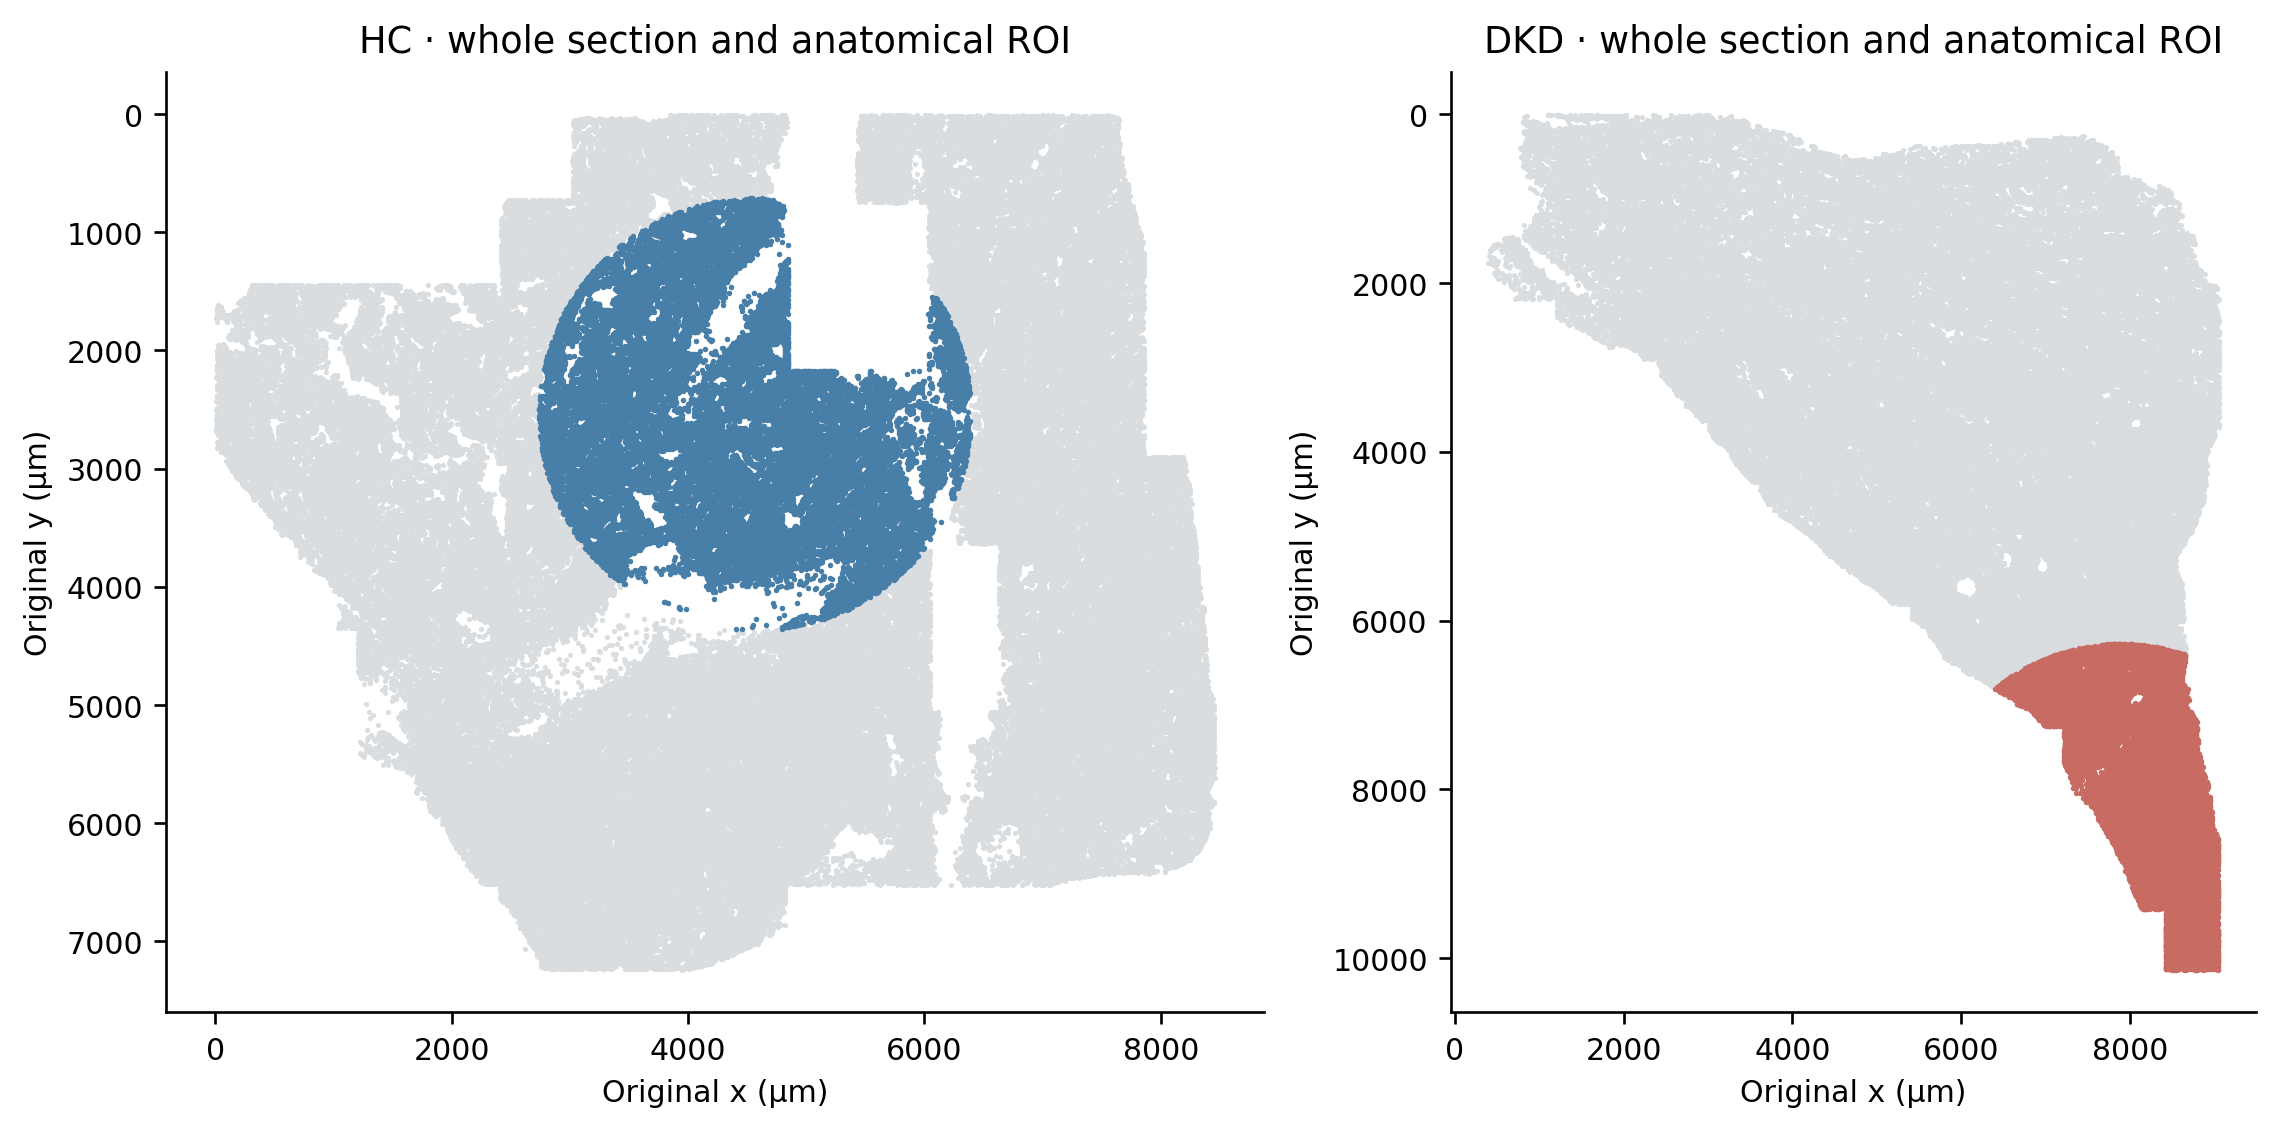

In [2]:
show(report.source_selection())

## 2 · 细胞类型、联合 niches、健康共有背景与新增状态

B：仅健康数据确定的背景 niche；R：超出组成相近的健康校准范围、并形成至少60个相连中心的异常状态。健康空间块与校准块清除共享物理邻居，阈值为相近健康组成中的99%分位；两组应用相同阈值和区域规则。R 不要求健康中强行清零。R 的类别和数量由候选表示无监督决定，未指定疾病应有几个 niche。

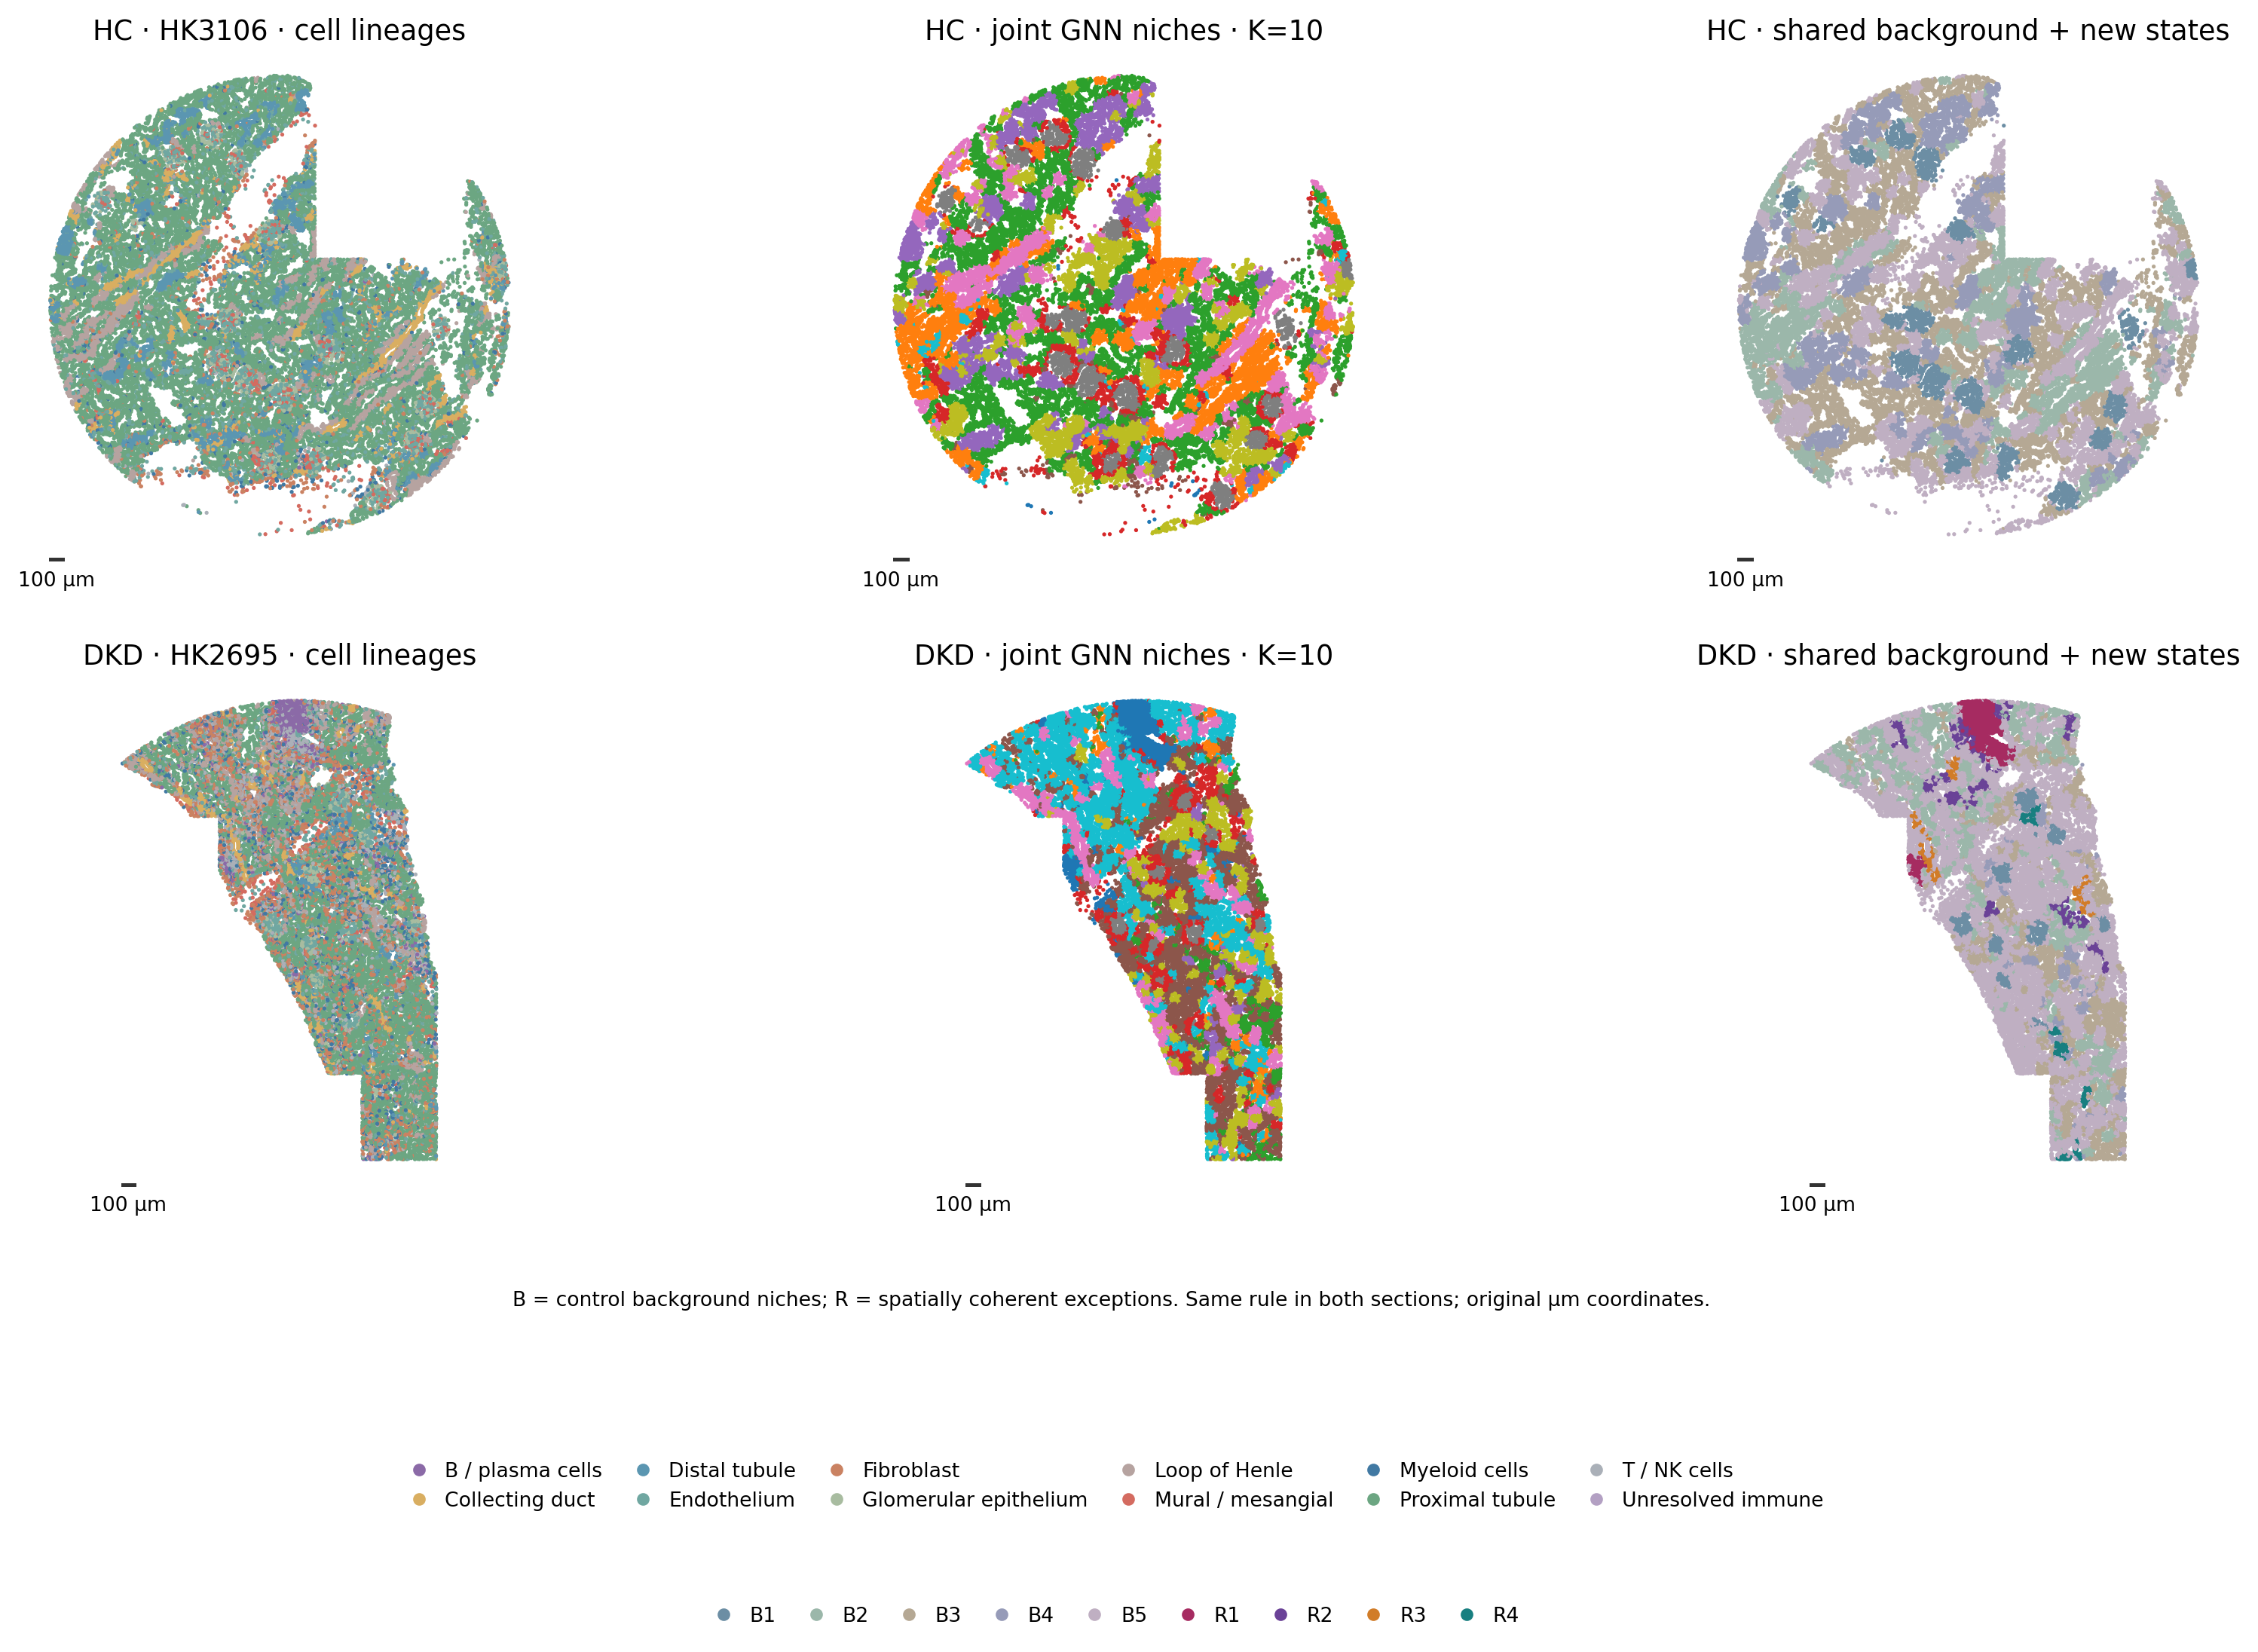

In [3]:
show(report.atlas())

## 3 · 新增 niche 在哪里、占多少？

占比以各组保留中心为分母；灰色是该切片的其他全部微环境。若没有候选通过预先规则，图中如实显示。

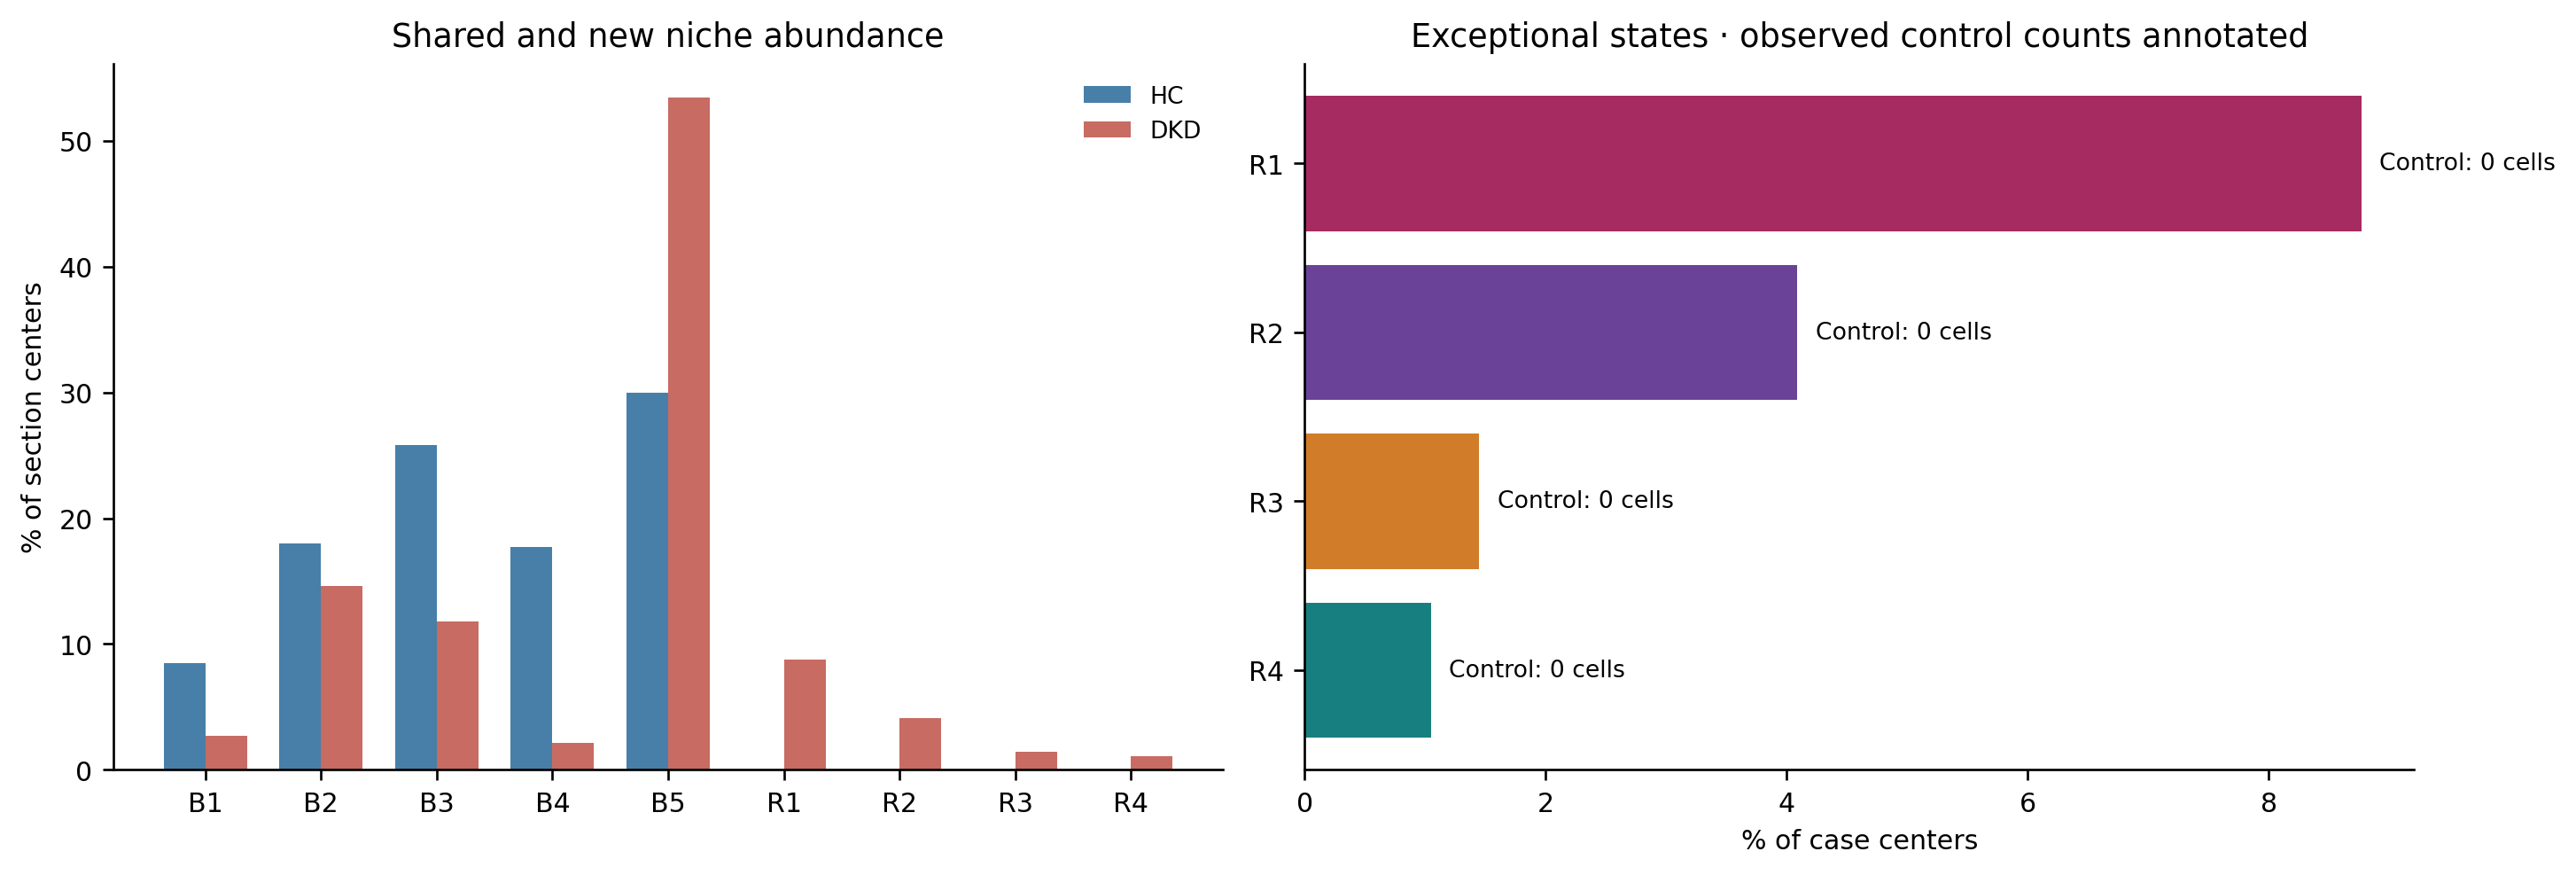

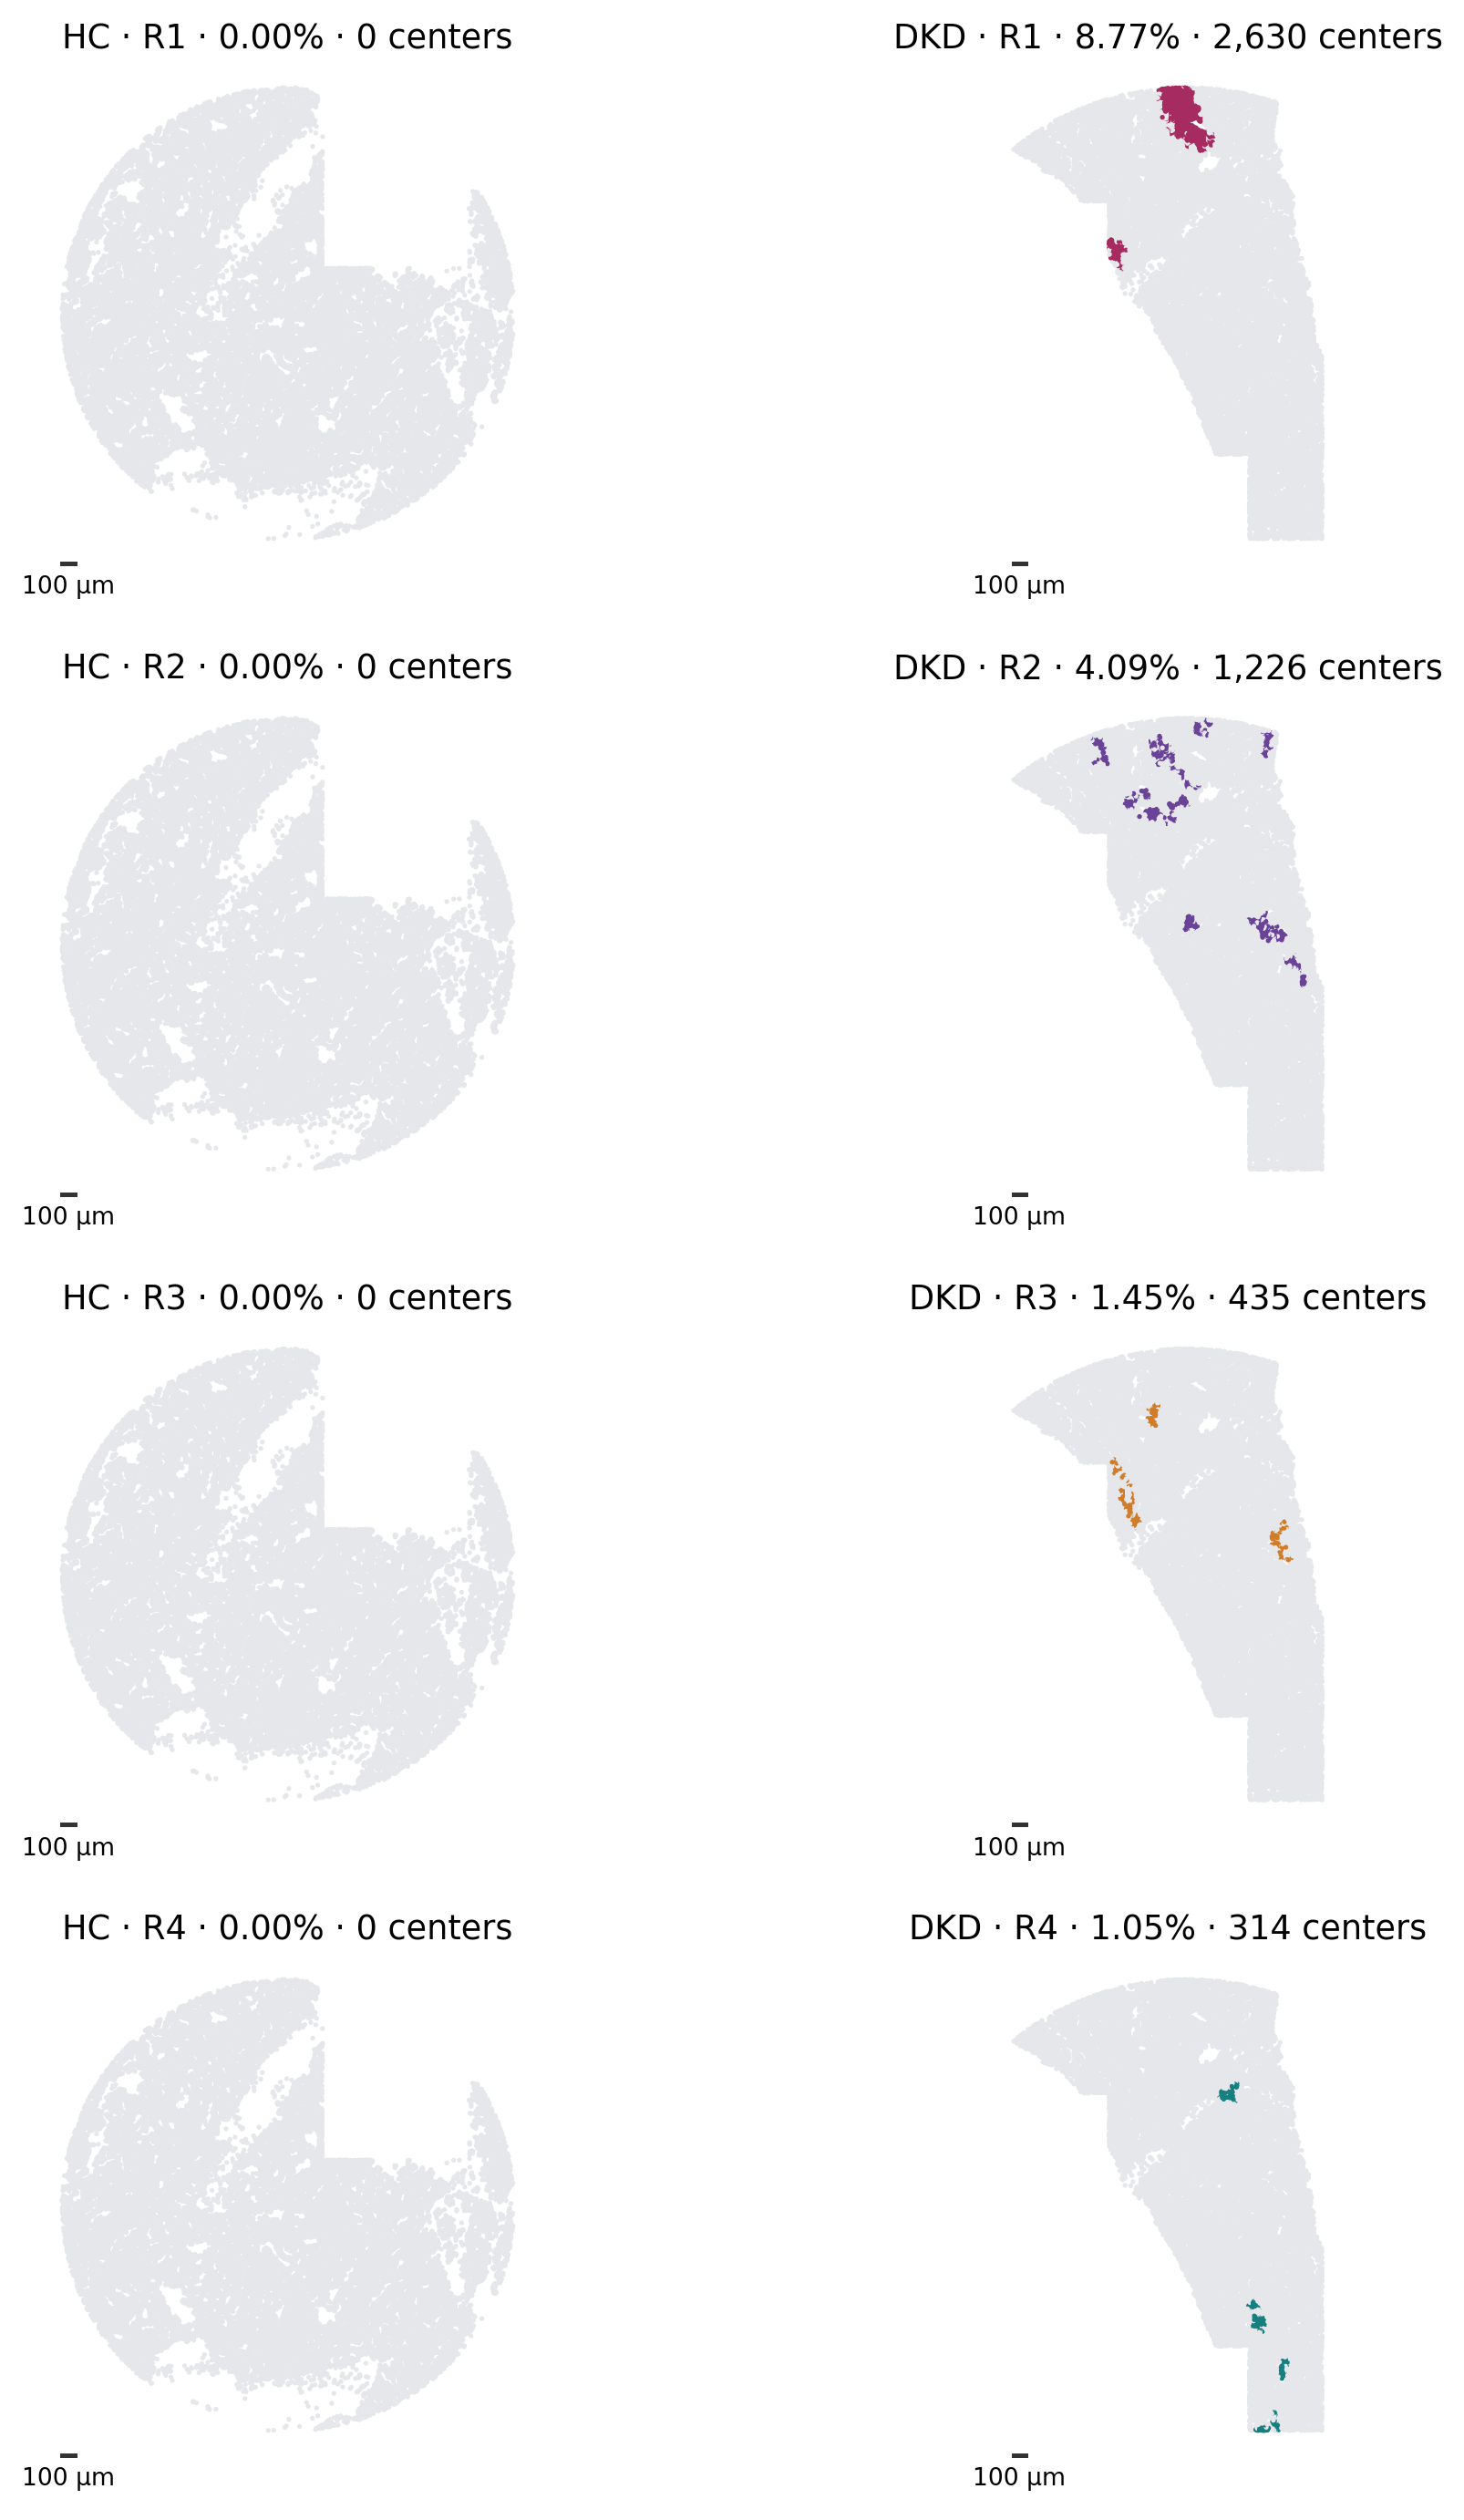

,Niche,主要细胞组成,健康中心数,病例中心数,组成匹配距离,同组成CCC差异支持
0,R1,B 60% · CD4+ 24% · CD8+ 6%,0,2630,0.762,False
1,R2,TAL 29% · Fibroblast 13% · CD4+ 11%,0,1226,0.456,False
2,R3,PC 33% · Fibroblast 13% · PT 12%,0,435,0.404,False
3,R4,PT 33% · DCT 14% · Fibroblast 13%,0,314,0.347,False


In [4]:
show(report.abundance())
show(report.spotlight())
display(report.evidence())

## 4 · 是否仅由细胞组成造成？

左：每个病例 R 从健康组成近邻中选择可用中心，同时展示实际匹配误差；距离不足够接近时，不解释为“同组成、通讯不同”。右：同一批配对中心中，观察 CCC 的相对谱差异，不只展示模型重构。组成接近仅指所定义的亲本类型，不等于精细细胞状态完全一致；检测深度和切片差异也需一起考虑。

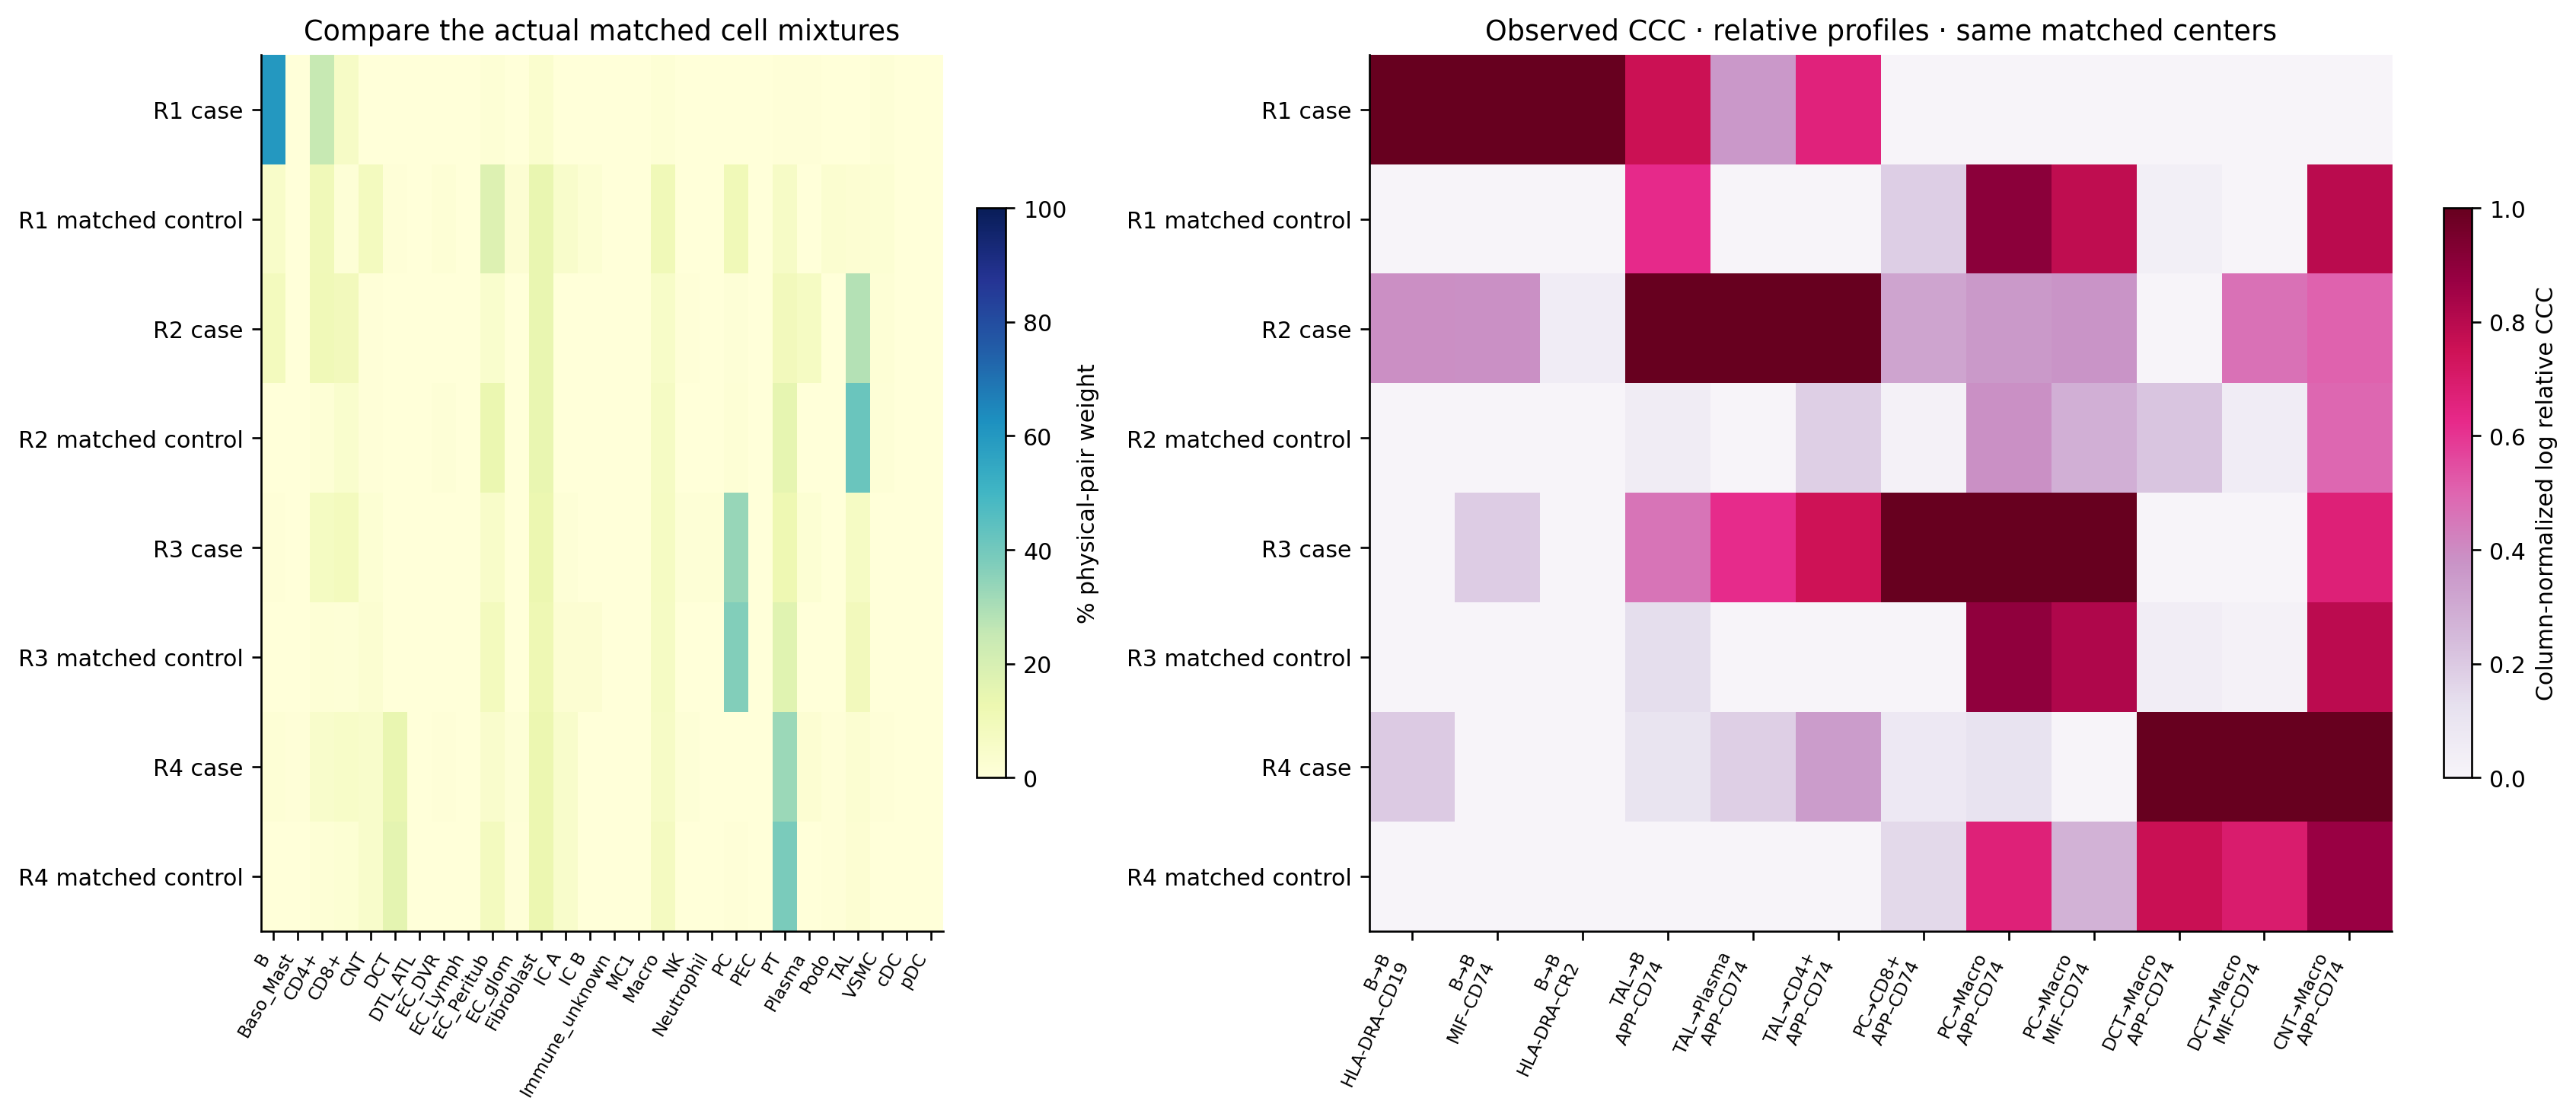

In [5]:
show(report.matched_communication())

## 5 · 每个 niche 的程序、组成与代表性有向 CCC

通讯程序共享32维 Z，代表性 sender→receiver→LR 来自 niche平均 Z 与 H 的乘积。此处表格仅列新增状态的 top10 CCC；全部背景与新增状态的表格保存在 NAS。

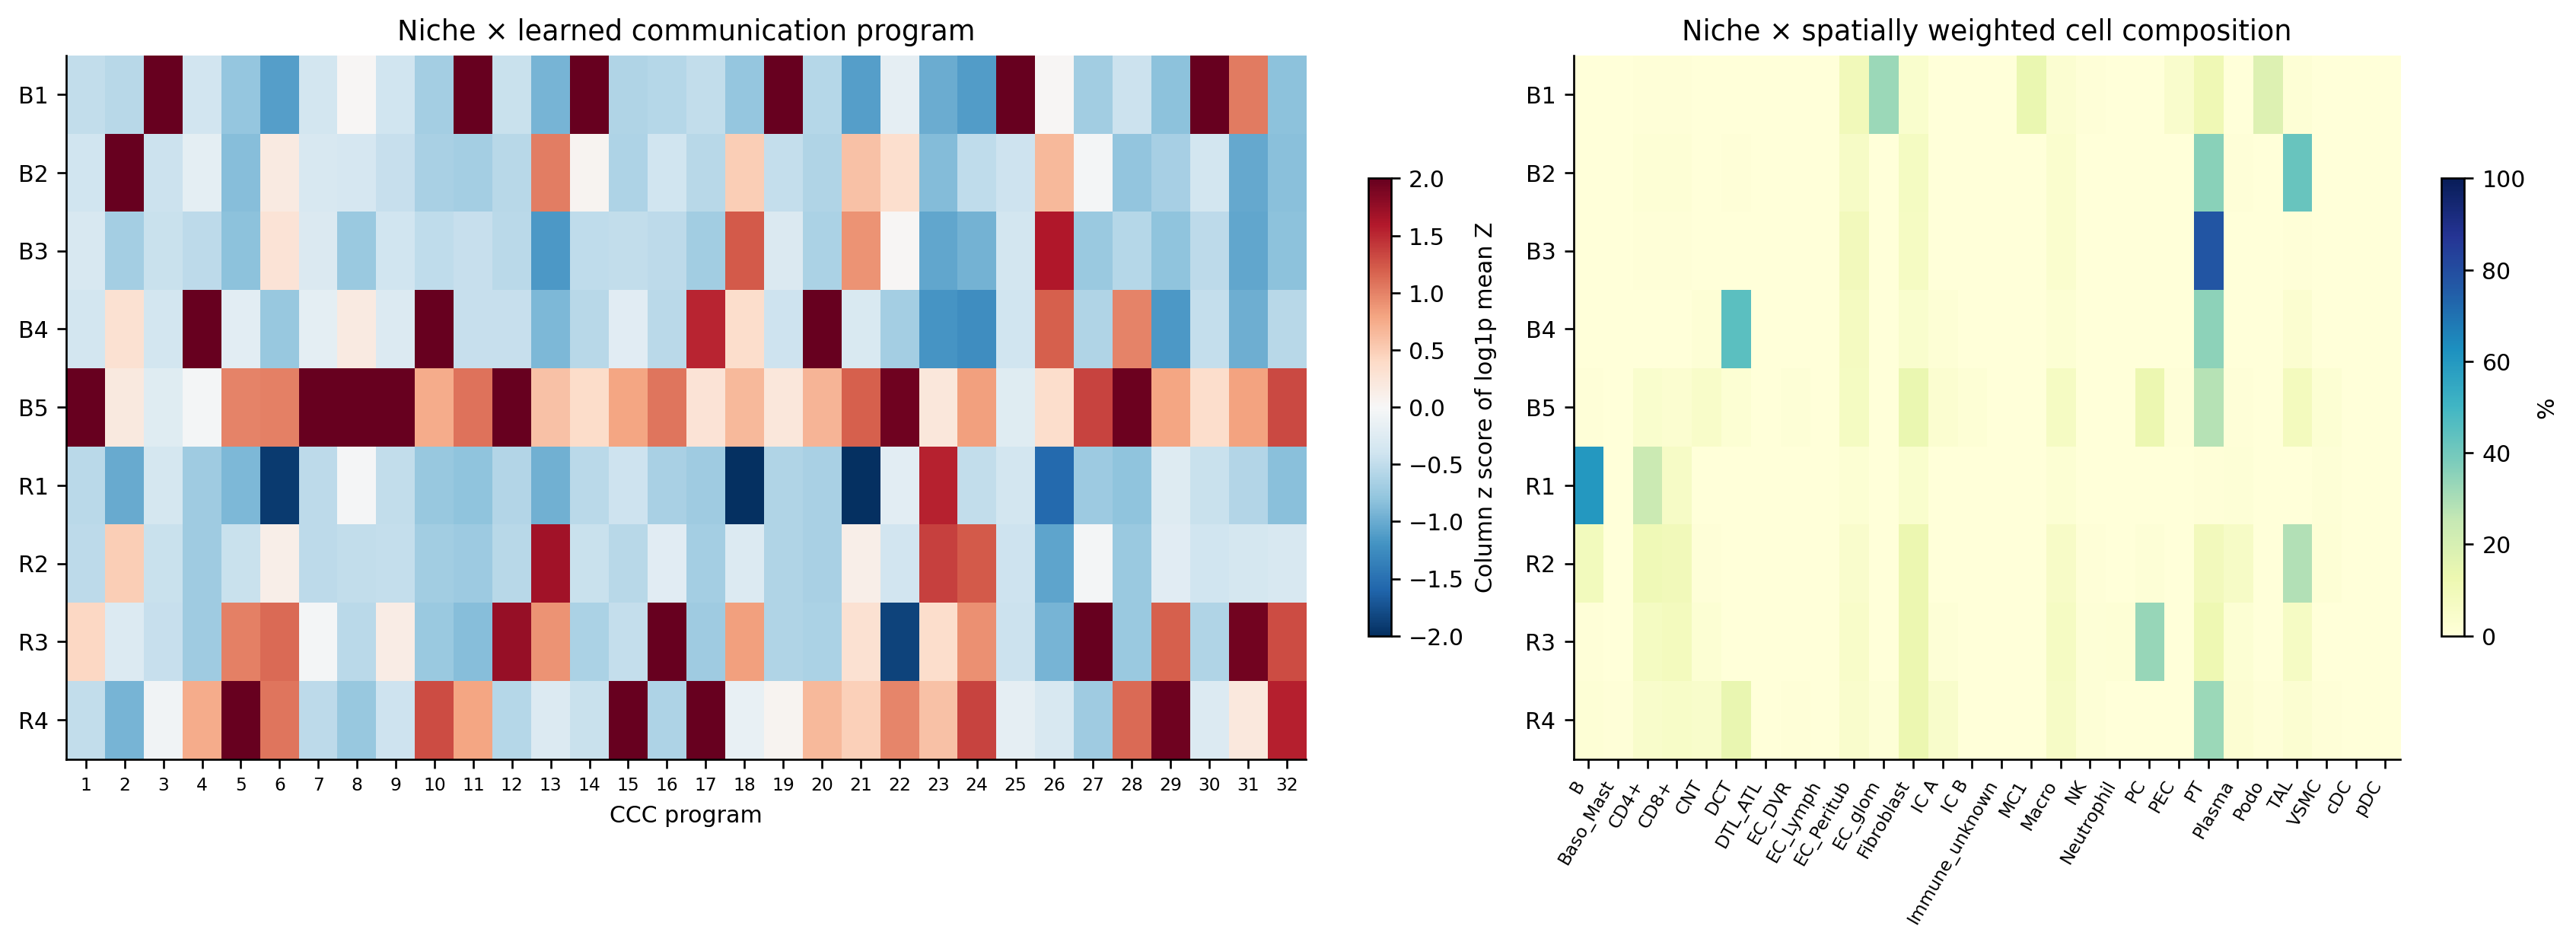

,niche,rank,sender,receiver,LR,reconstructed_CCC
50,R1,1,PT,B,APP–CD74,0.244
51,R1,2,EC_Peritub,B,APP–CD74,0.229
52,R1,3,TAL,B,APP–CD74,0.169
53,R1,4,EC_Peritub,Macro,APP–CD74,0.149
54,R1,5,EC_Peritub,CD8+,APP–CD74,0.123
55,R1,6,EC_Peritub,CD4+,APP–CD74,0.114
56,R1,7,Fibroblast,B,APP–CD74,0.111
57,R1,8,PT,B,MIF–CD74,0.108
58,R1,9,PT,CD8+,APP–CD74,0.096
59,R1,10,B,Fibroblast,HLA-DRA–CD81,0.091


In [6]:
show(report.programs())
display(report.top_CCC())

## 6 · 训练、背景 K 选择与原 CCC 重构

全部报告中心联合优化，训练子集监测不称作独立验证。背景 K 仅用健康校准数据的无监督分数，不按病例独有数量选择。

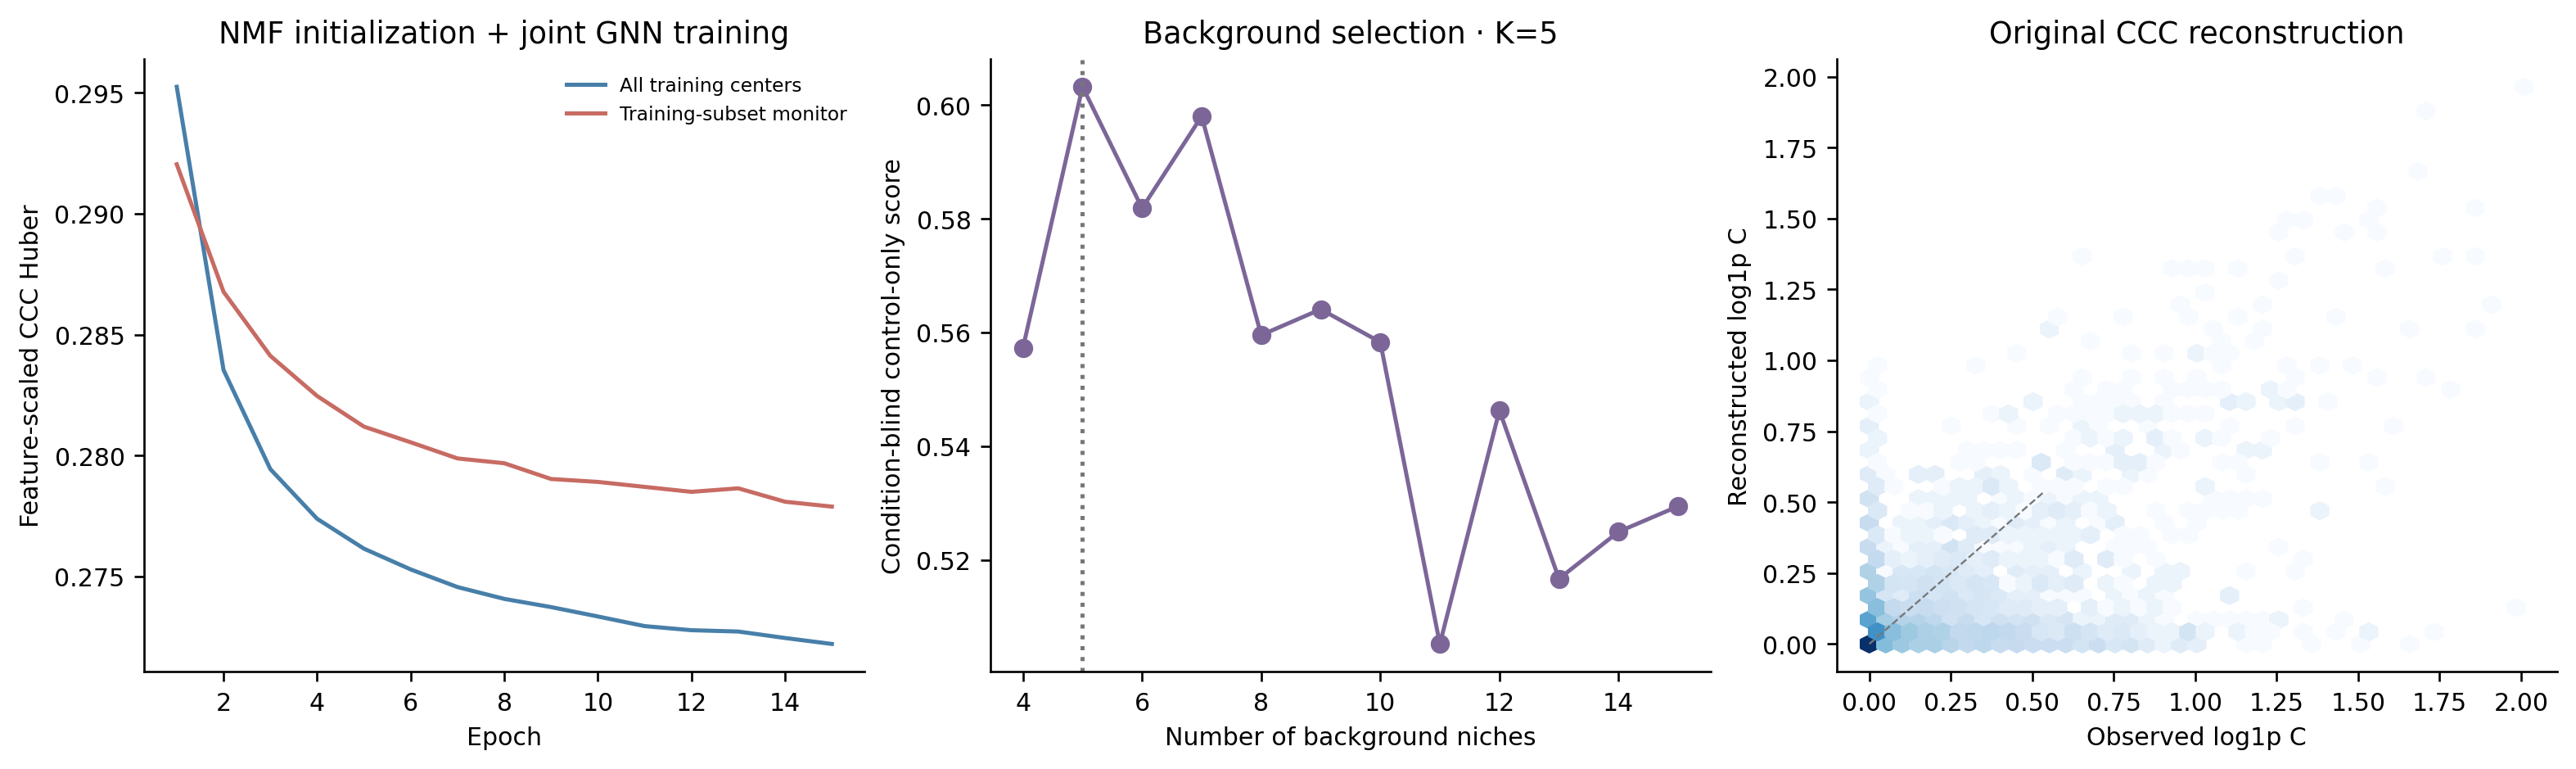

Model, matrices, figures and source tables: /home/nas3/biod/xueshuailin/CCC_Phe/workspace/outputs/kidney_dkd_5k/HK3106_HK2695


In [7]:
show(report.training())
print('Model, matrices, figures and source tables:',OUTPUT)

## 7 · Niche 内哪些细胞相邻，哪些细胞发生通讯？

借鉴 [Harmonics 的病例—对照下游分析](https://harmonics-tutorial.readthedocs.io/en/latest/Case-control%20studies/2.1%20Xenium_PF_Vannan2025/runHarmonics.html)，沿着 **niche → 局部细胞关系 → LR → 同类型细胞状态** 展开。保持已训练模型、niche 和原始 CCC 不变。

上排：原 KNN30 内物理细胞对去重后的空间接触富集；100µm 局部块内置换细胞类型199次，保留局部组成。黑点为该切片空间置换 BH q<0.05，空白是支持不足。下排：原始有向 CCC 在发送—接收类型间的分布，与空间接触分别展示。每列显示该 niche 接触最多的8类细胞；上下排颜色含义不同。

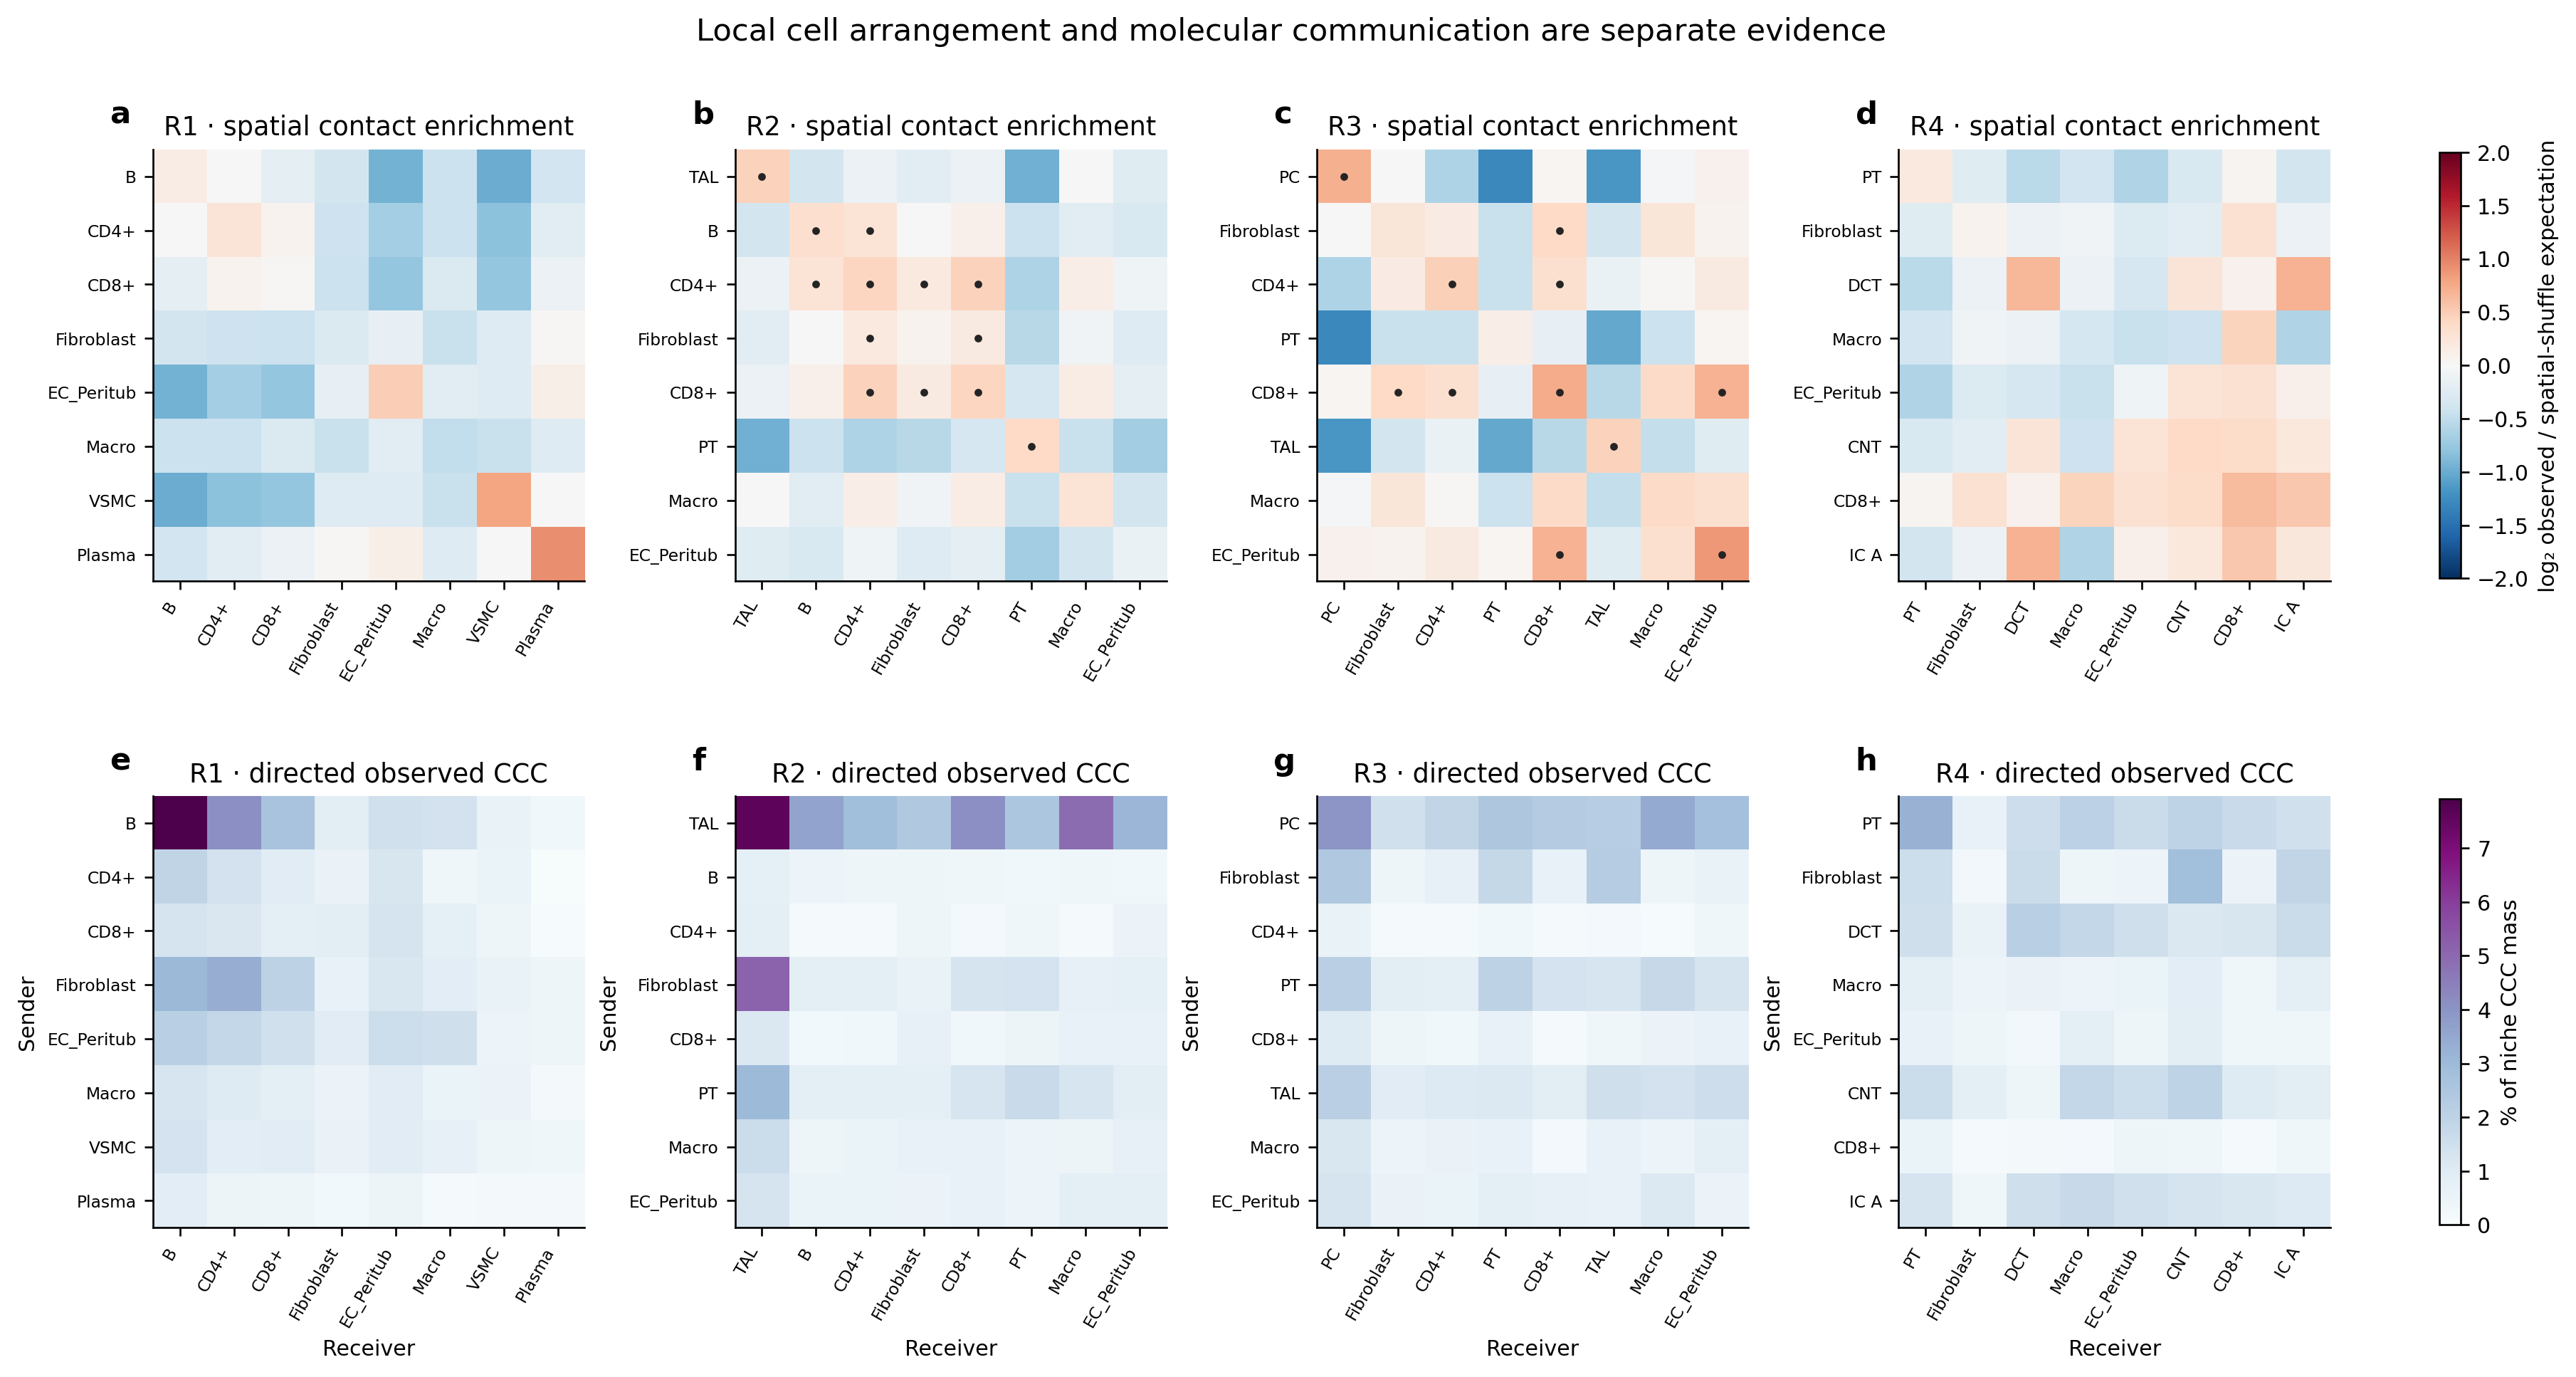

In [8]:
from phenoniche.cohorts.kidney_downstream import ensure_downstream
from phenoniche.cohorts.kidney_downstream_reporting import KidneyDownstreamReport
downstream_path=ensure_downstream(OUTPUT)
downstream=KidneyDownstreamReport(OUTPUT)
show(downstream.contacts_and_CCC())

## 8 · R2：从空间位置到具体 LR 的变化

左上为整片 R2，方框定位其最密集区域；右上是该区真实细胞和原图中的 TAL→CD8+ CXCL14–CXCR4 表达阳性邻近候选（按原空间权重与实测 RNA 排序，最多25条），箭头仅表示候选方向。左下在**同一发送—接收类型**内部比较 LR 相对谱，使用已有配对中心、排除任一侧没有物理配对机会的配对，CCC 仍沿用原 opportunity normalization；右下直接比较相同细胞类型的实测 ligand/receptor RNA。不是把预测值当作独立表达证据。

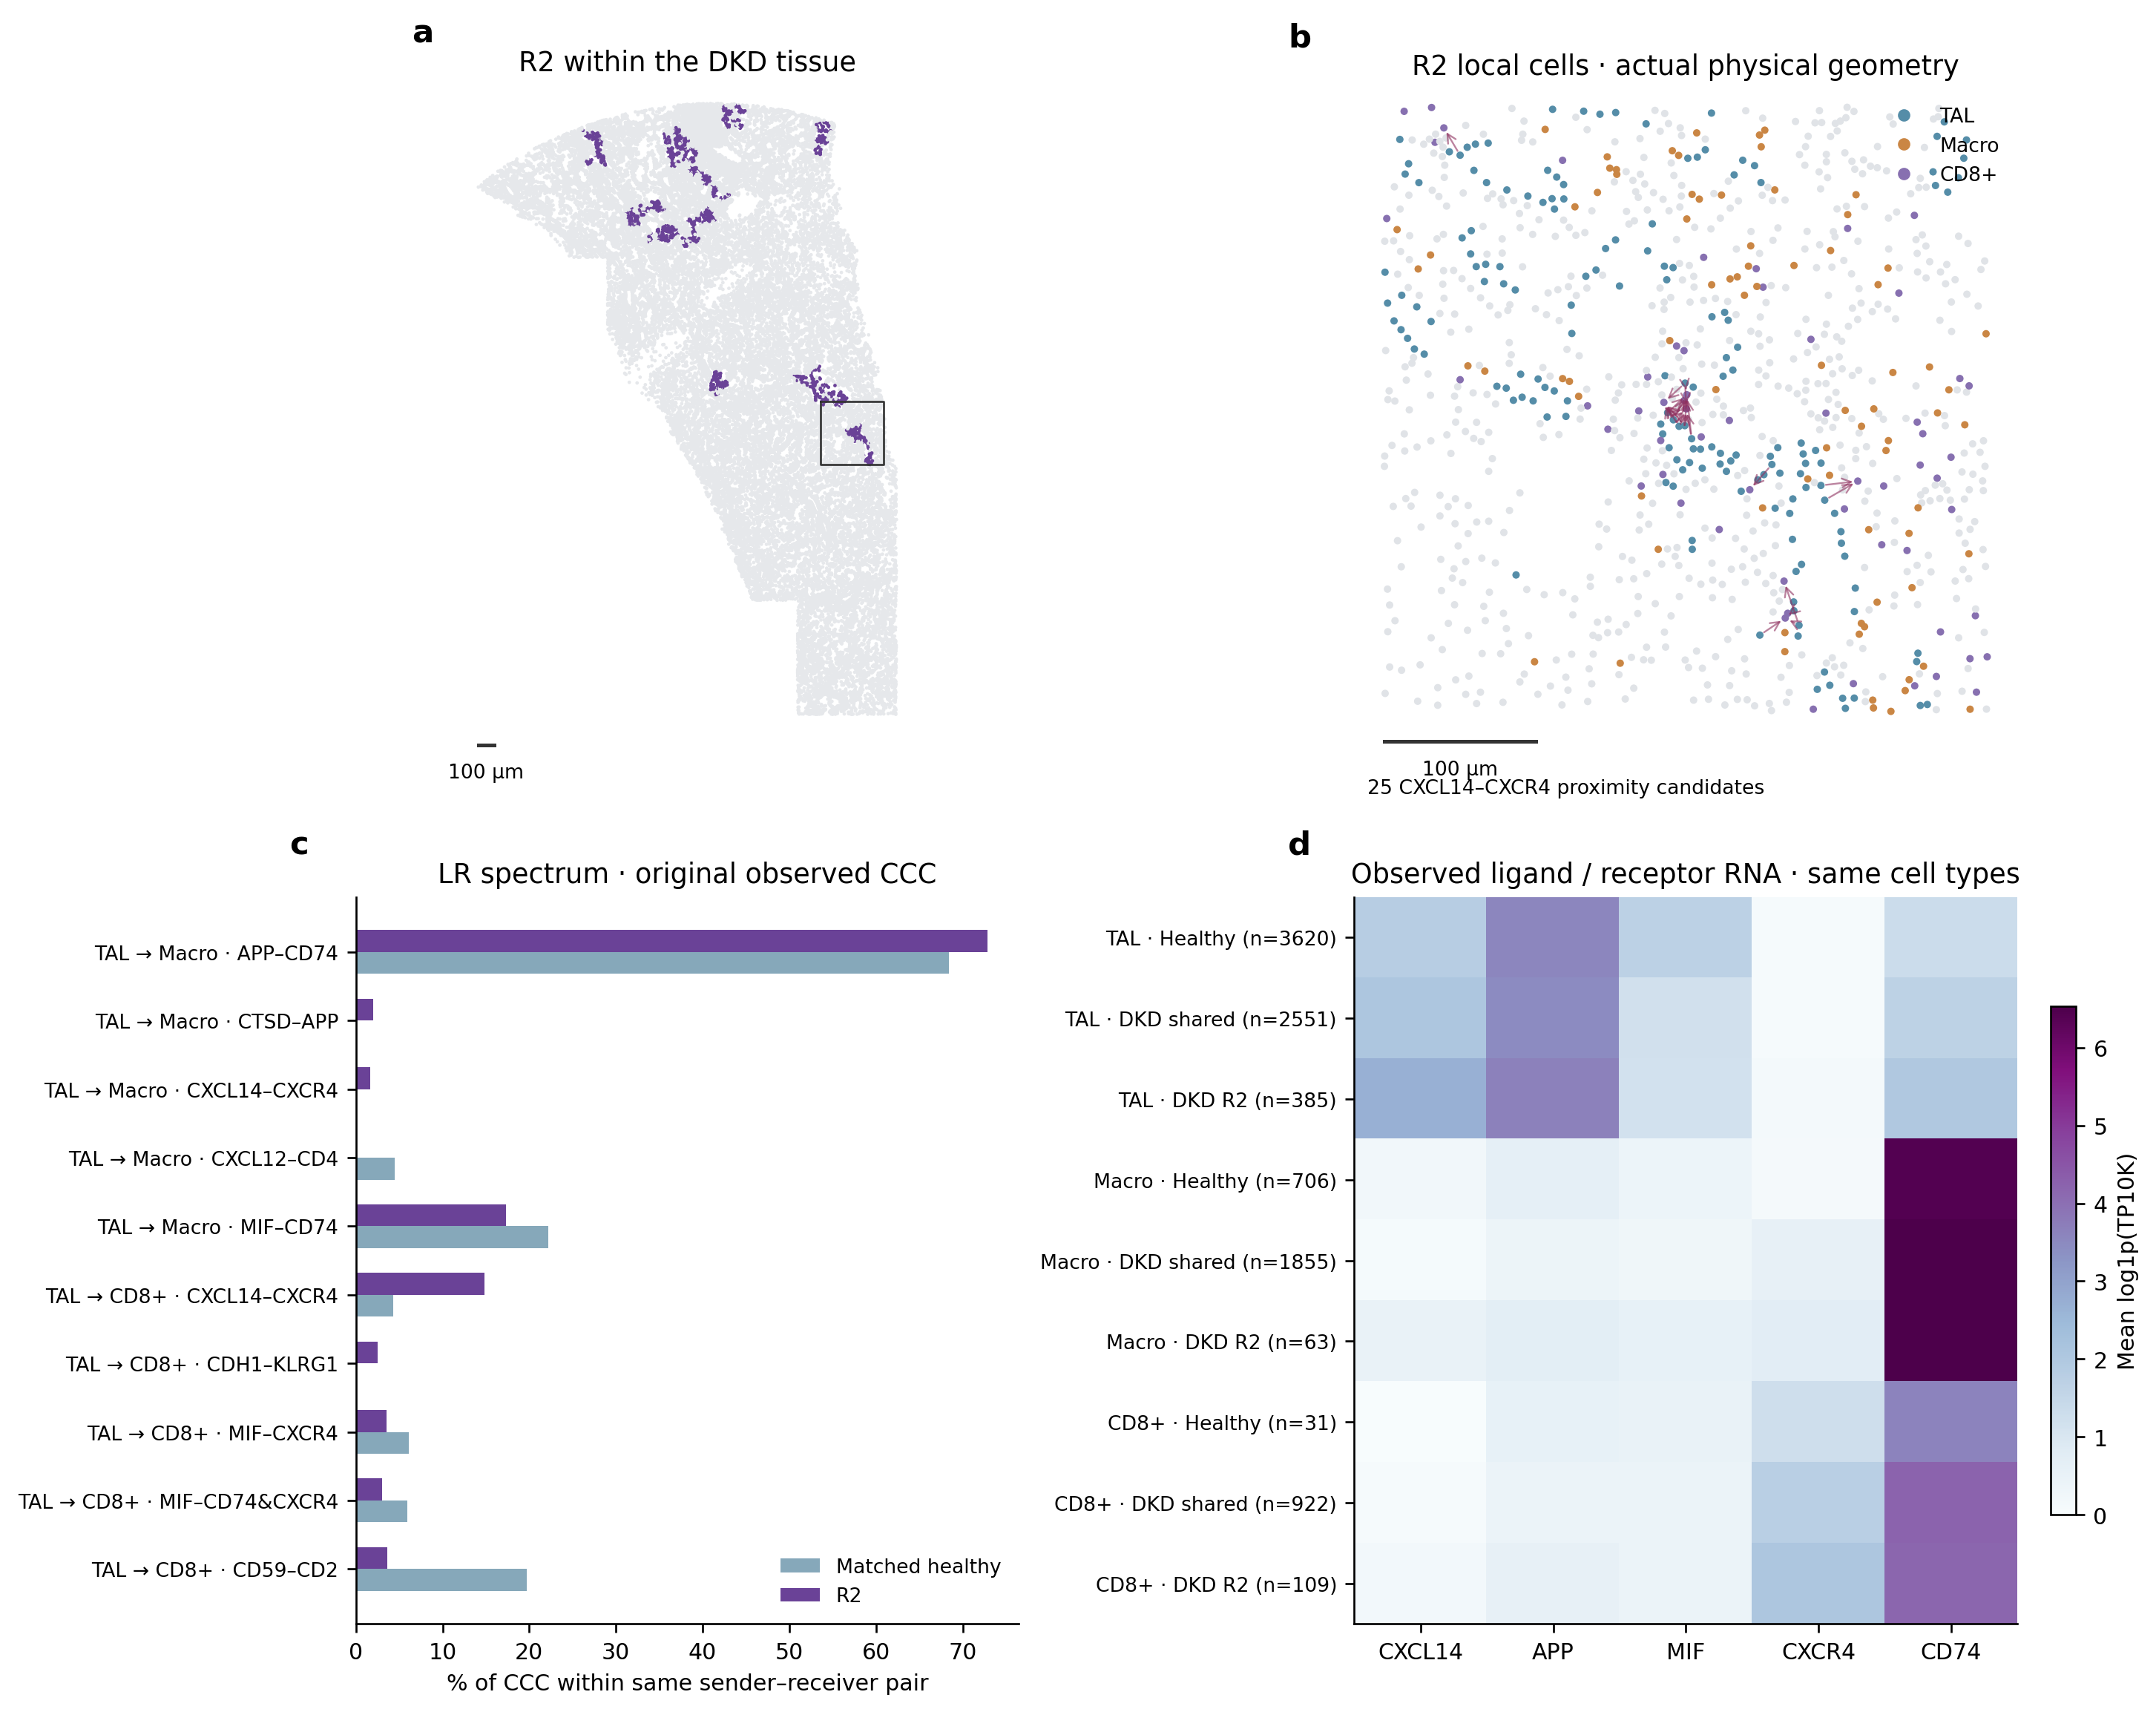

In [9]:
show(downstream.r2_mechanism())

## 9 · R2 的 TAL 是否处于不同表达状态？

仅用 TAL 实测表达构建 PCA/UMAP，再叠加 niche 和原作者 TAL/iTAL 精细注释。两个散点图是同一嵌入；不把横断面图解释为分化轨迹。下排给出同类型细胞的实测 marker 表达及 iTAL 比例（标注细胞数），对比全片和 niche 局部。所有参与细胞去重，仅统计报告中心。

基因差异以 **DKD R2 TAL 对比同一 DKD 切片共有 B niches 内 TAL** 为主，减少健康/疾病切片间技术差异的影响。表格是表达效应量，不将细胞数当作独立患者数做疾病显著性检验。

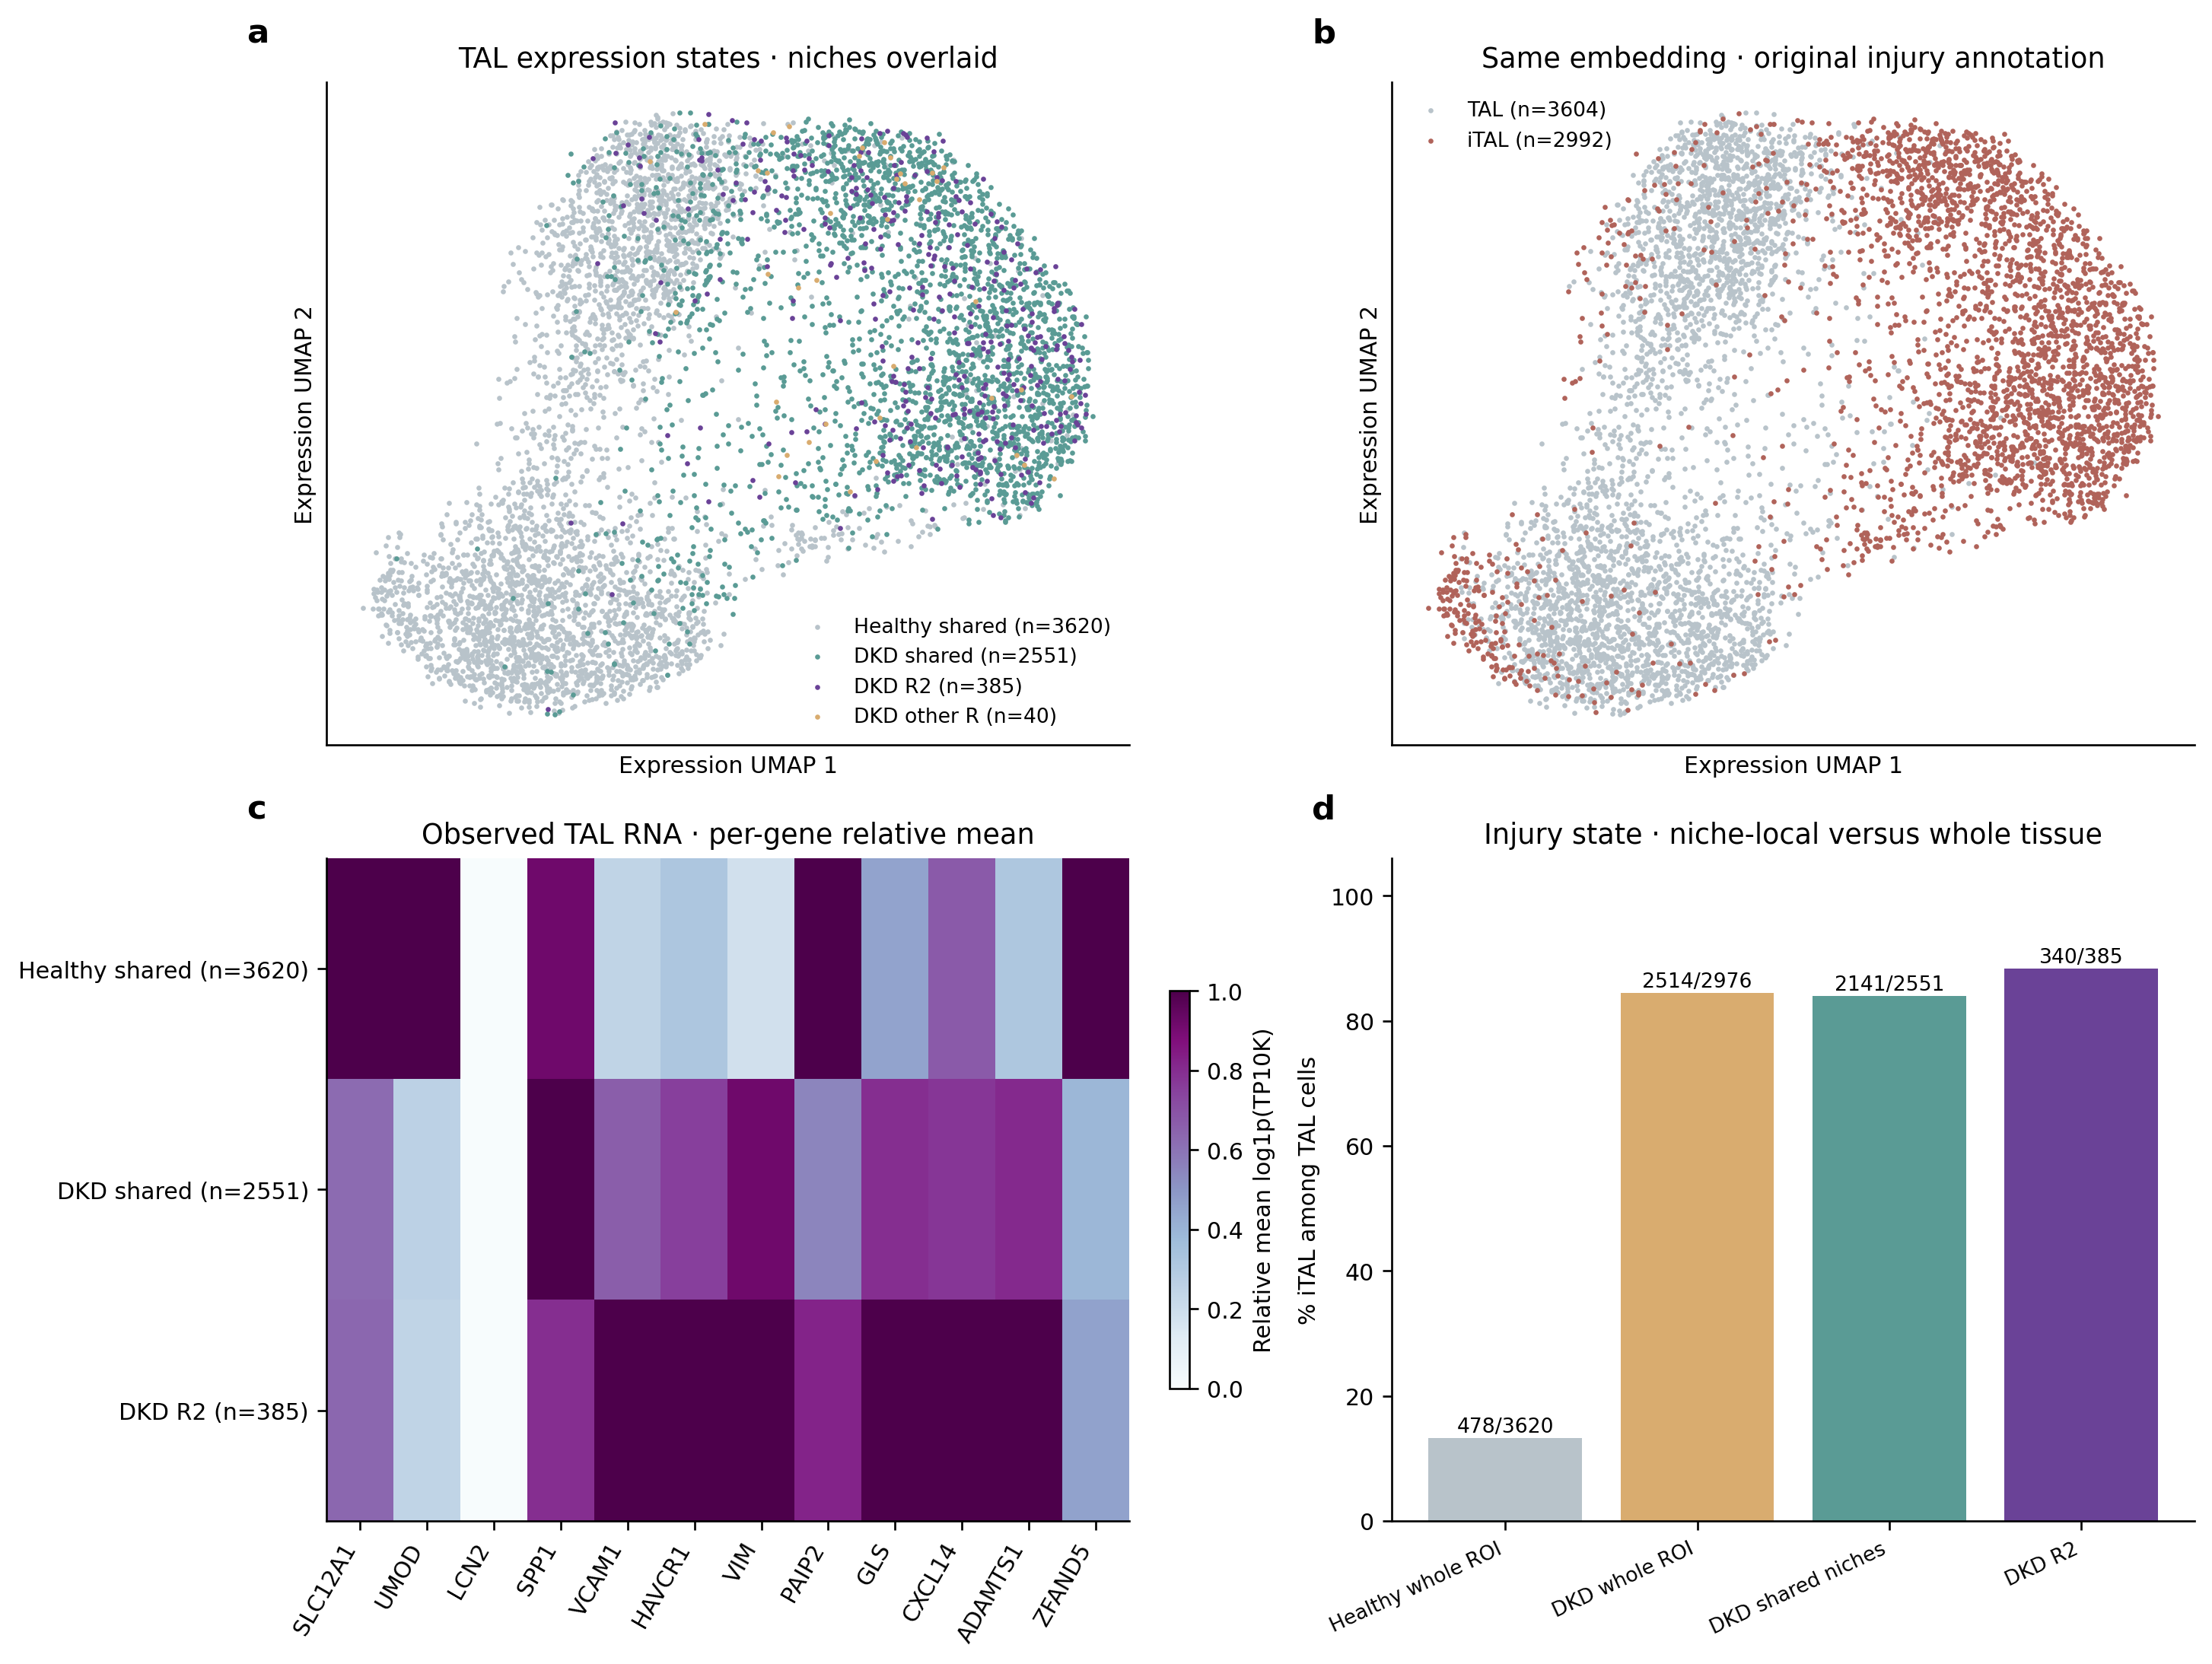

,gene,log2FC,niche_detection,background_detection
8899,PAIP2,0.725,0.218,0.152
7376,GLS,0.690,0.218,0.183
6625,CXCL14,0.627,0.582,0.480
5521,ADAMTS1,0.495,0.275,0.227
10825,ZFAND5,0.447,0.247,0.218
10789,YWHAQ,0.365,0.221,0.180
10669,VAV3,0.330,0.210,0.177
7846,IL6ST,0.329,0.226,0.209
10026,SOX9,0.328,0.226,0.204
9057,PIGR,0.326,0.561,0.489


In [10]:
show(downstream.tal_states())
display(downstream.top_genes())

## 10 · Niche 中的细胞状态对应哪些通路？

每个 niche/细胞类型对比同一 DKD 切片共有 B niches 中的相同类型，选择检测率≥10%、log₂FC≥0.25 的前100个上调基因；使用真实 [MSigDB Hallmark](https://www.gsea-msigdb.org/gsea/msigdb/human/collections.jsp#H) 2020 基因集。背景为对应类型中实际检测到的 panel 基因；覆盖率、交集基因及全部检验保存在 NAS 表格。图中颜色为该基因集中实测基因的平均 log₂FC，圆点大小为覆盖基因数；每组选择覆盖≥10个基因、平均变化最大的两个模块并取并集。黑边仅标注全部 context×pathway 基因集重叠检验 BH q<0.05 的模块；未通过时如实标注，表达变化不等同于显著通路富集。这里的 q 不是人群疾病关联。

本例一张健康、一张 DKD，不制造病理严重度相关性。保存的 niche 内/全片损伤比例为未来有临床标签的队列分析提供直接对应的指标。

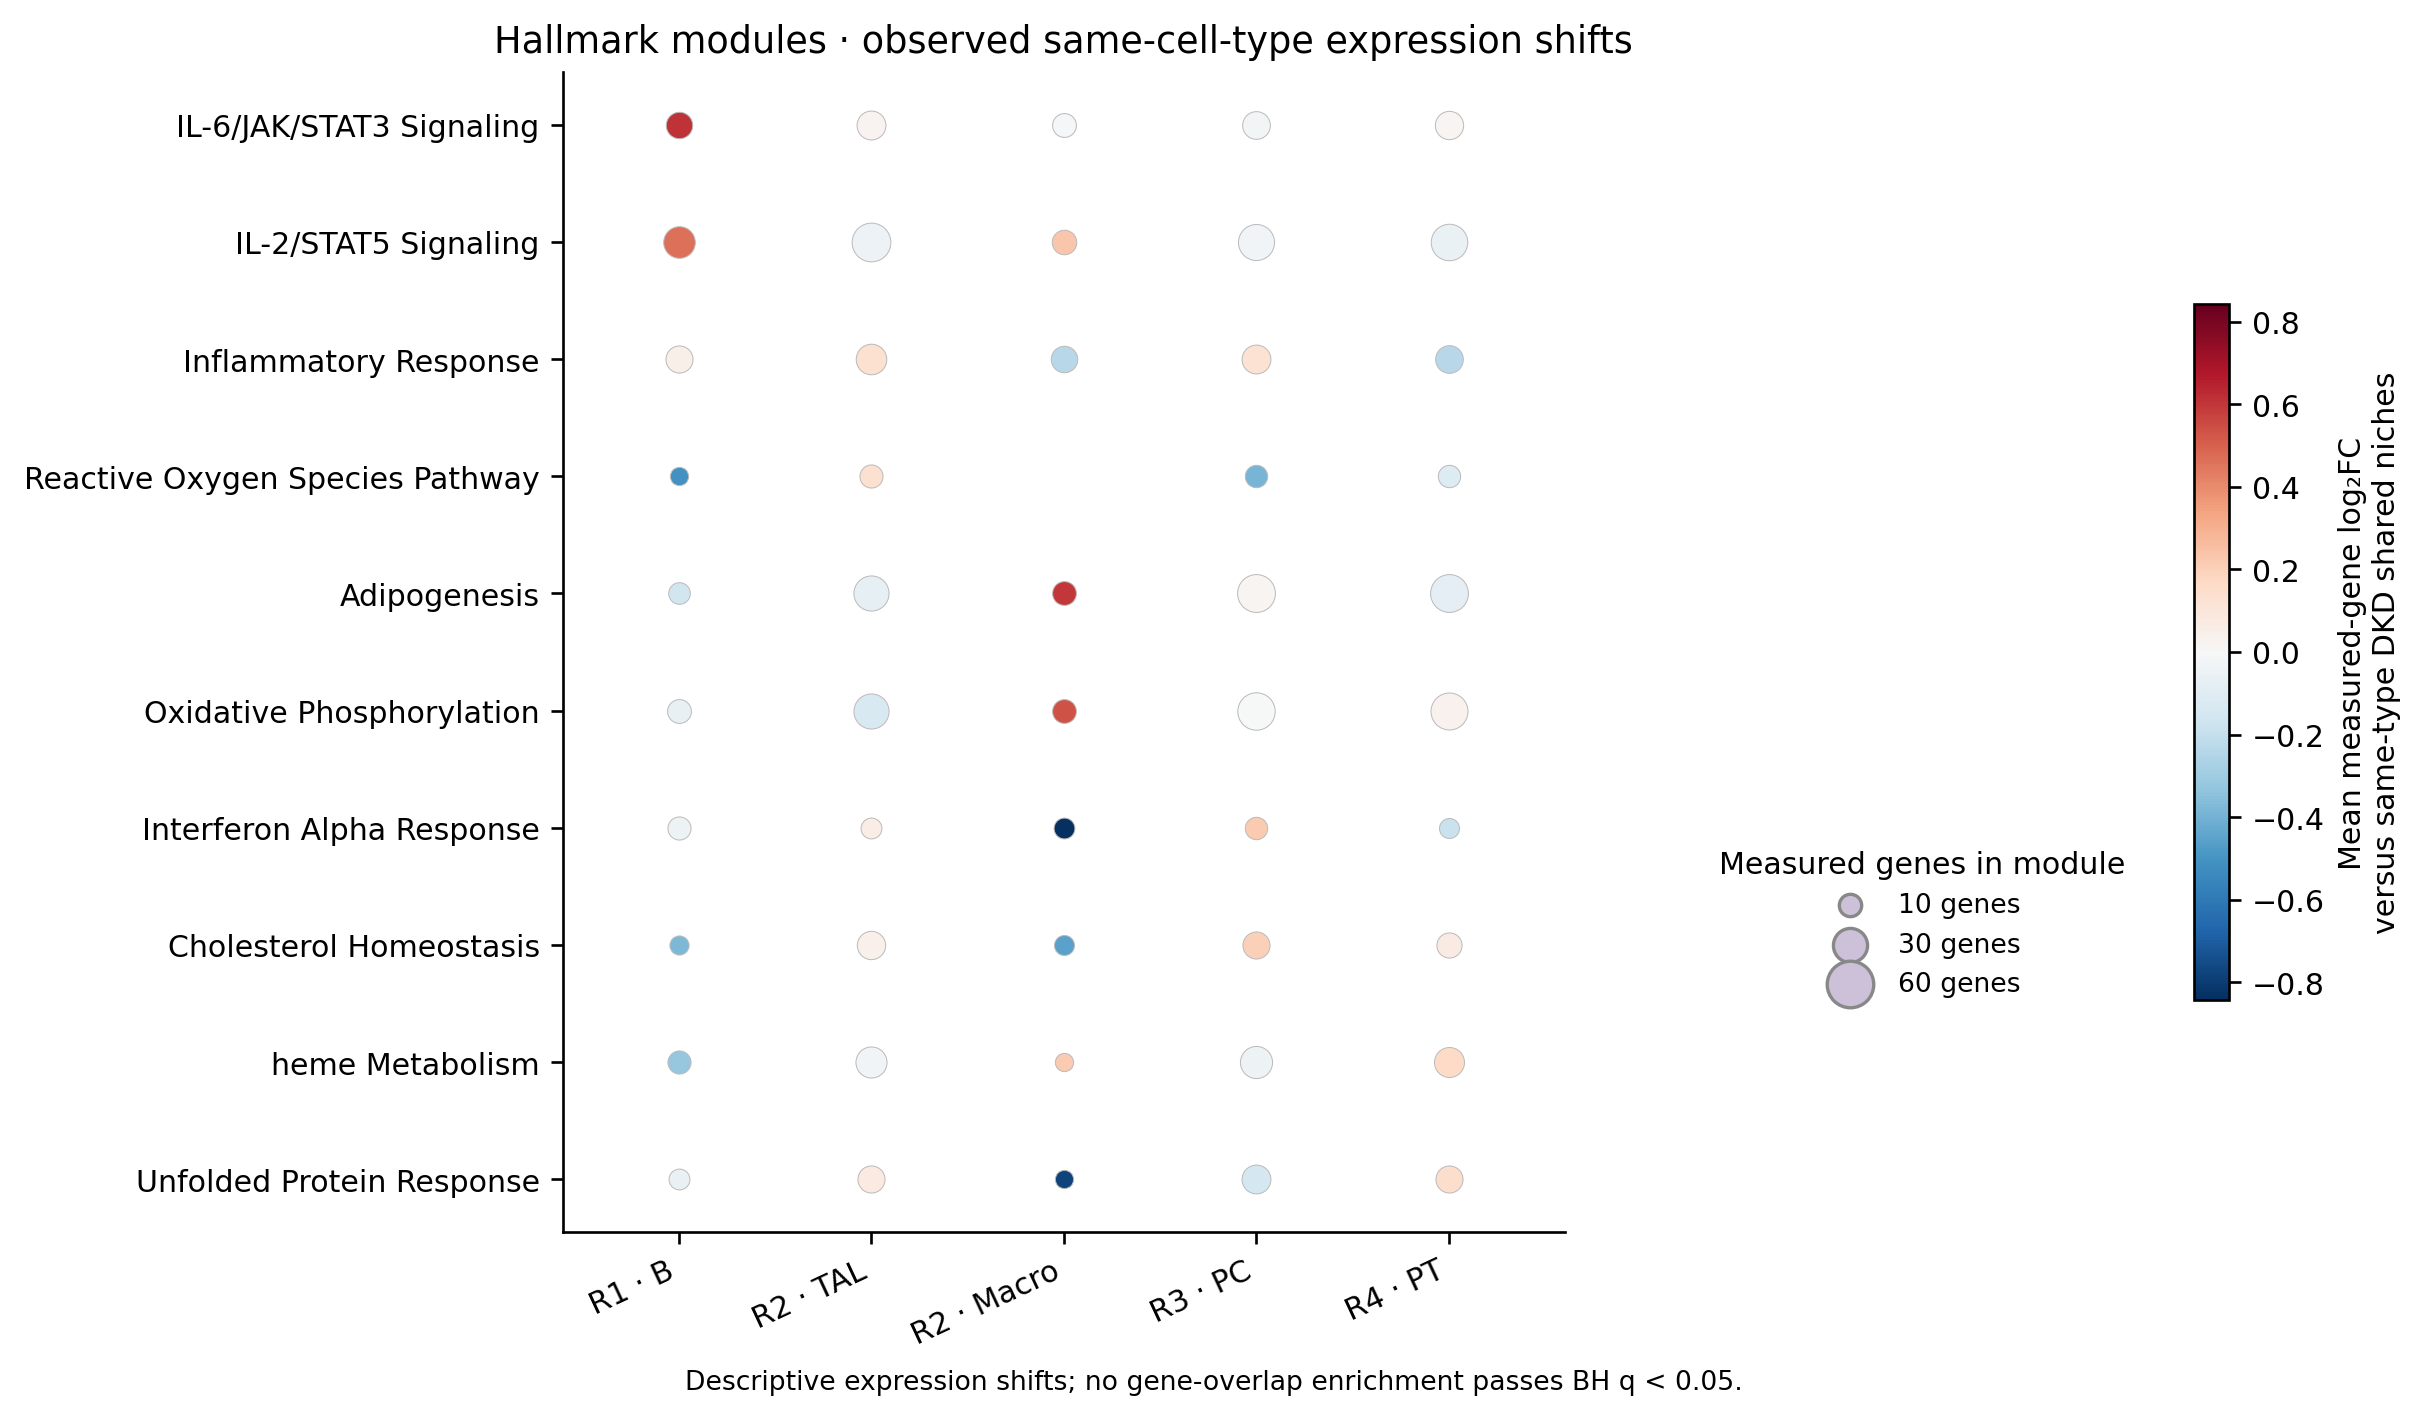

Downstream figures: /home/nas3/biod/xueshuailin/CCC_Phe/workspace/outputs/kidney_dkd_5k/HK3106_HK2695/figures
Source tables: /home/nas3/biod/xueshuailin/CCC_Phe/workspace/outputs/kidney_dkd_5k/HK3106_HK2695/downstream


In [11]:
show(downstream.pathways())
print('Downstream figures:', OUTPUT/'figures')
print('Source tables:', downstream_path)

## 11 · R2 接收细胞：哪些基因和响应状态改变了？

主比较固定为 **R2 CD8⁺ / 巨噬细胞，对比同一 DKD 切片共有 B niches 内的相同类型**。左侧展示实测 RNA 上调基因（不包含任何 CCC ligand/receptor、免疫球蛋白基因，R2检测率≥15%、共有背景≥5%）；右侧用真实 Hallmark 基因集计算实际可测的非 LR 基因表达评分。每组显示绝对变化最大的6个模块，包括升高和降低。评分以同类型 DKD 共有背景标准化，不是模型预测的表达，也不直接等于通路激活。

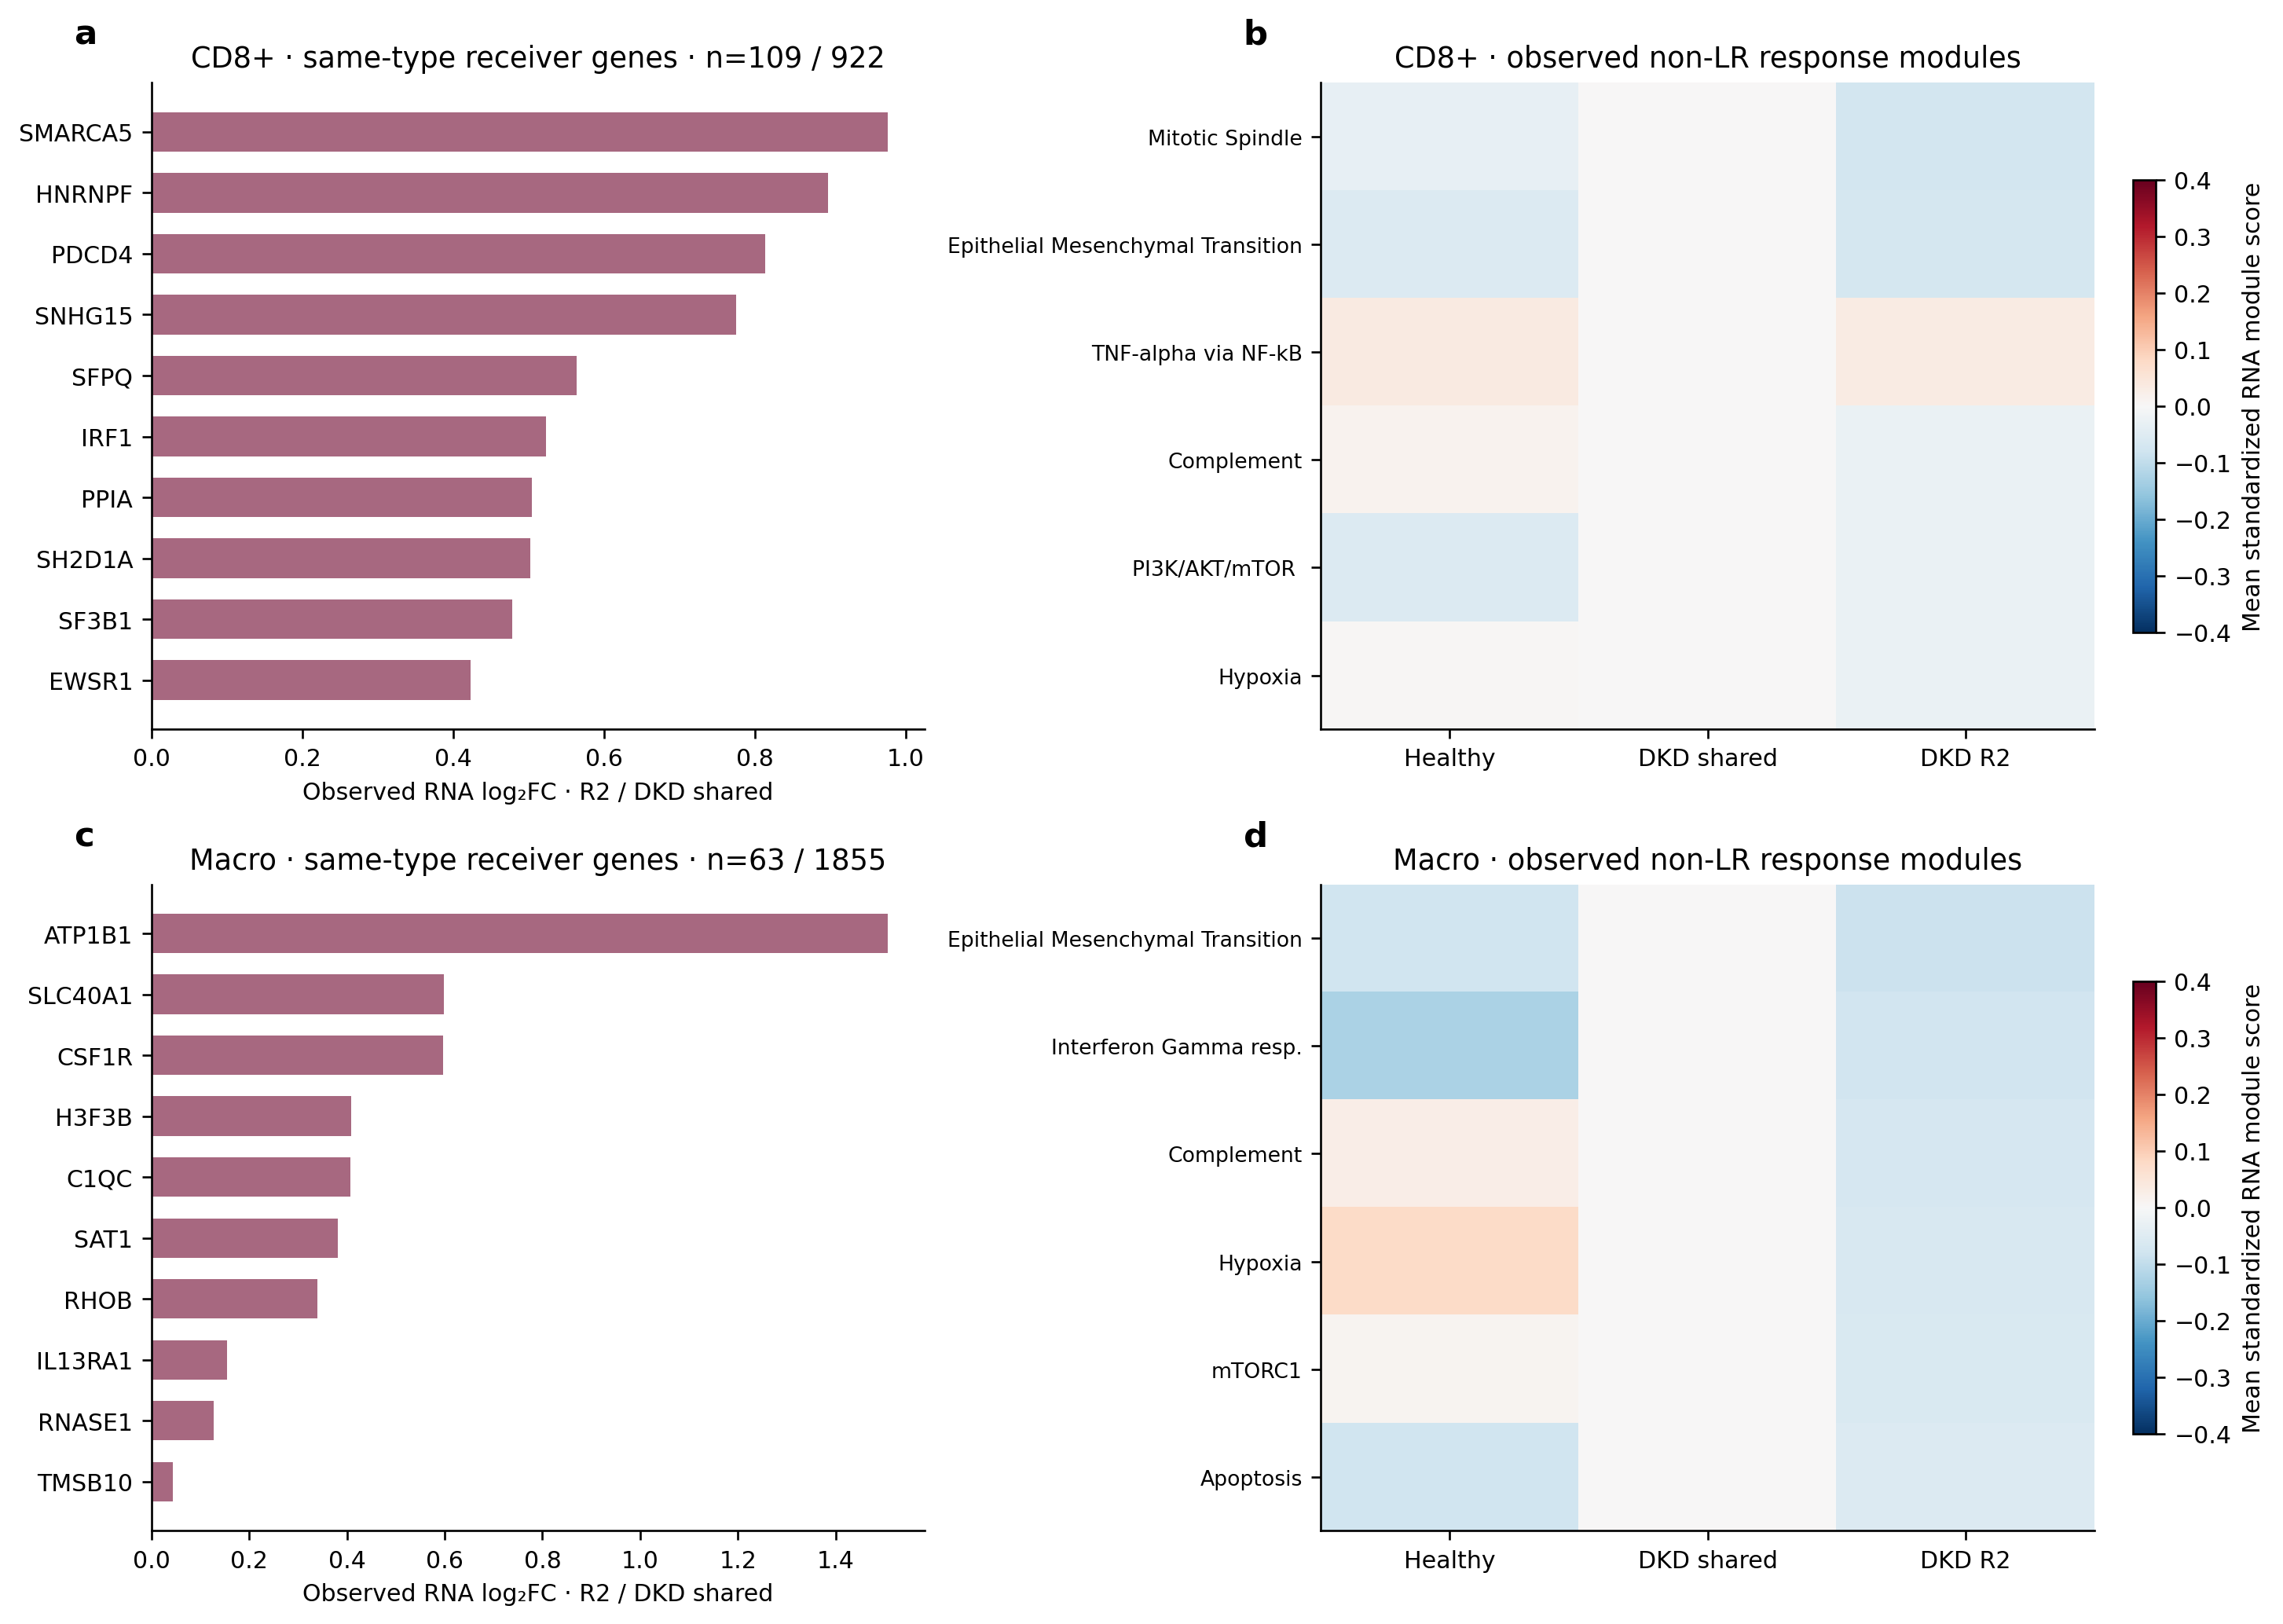

In [12]:
from phenoniche.cohorts.kidney_response import ensure_receiver_response
from phenoniche.cohorts.kidney_response_reporting import KidneyResponseReport
receiver_path=ensure_receiver_response(OUTPUT)
receiver=KidneyResponseReport(OUTPUT)
show(receiver.receiver_states())

## 12 · 把候选 ligand 与接收端的真实表达接起来

使用已核对官方校验值的 [NicheNet-v2 人类先验](https://zenodo.org/records/7074291)，借鉴其[按接收端可测背景评估 ligand 的思路](https://github.com/saeyslab/nichenetr/blob/master/vignettes/ligand_activity_single_cell.md)。先固定同类型 DKD 共有背景检测率≥5%的非 LR 基因，再按真实先验分数选最多30个可测靶基因，不使用 R2 差异选择评分基因。全人类先验 top100 的实际覆盖数、原始权重和排名另存表，面板投影不会被说成强机制证据。

左：候选 ligand 的先验靶基因联系（行内相对权重）；右：对应接收细胞的**实测**表达，以同类 DKD 共有背景标准化。仅展示这些固定候选靶基因中 R2 检测率≥10%、表达变化最大的10个。空白表示不在该 ligand 固定投影的30个靶基因中。

NicheNet 是无激活方向、非 receptor 特异的间接调控潜力；不将这些联系画成已证实的直接作用。CXCL14–CXCR4 的功能方向在文献中存在不同结果（[研究1](https://pubmed.ncbi.nlm.nih.gov/25451233/)、[研究2](https://pubmed.ncbi.nlm.nih.gov/25372750/)），因此保留为候选调节联系，不称作确定的 CXCR4 激活。

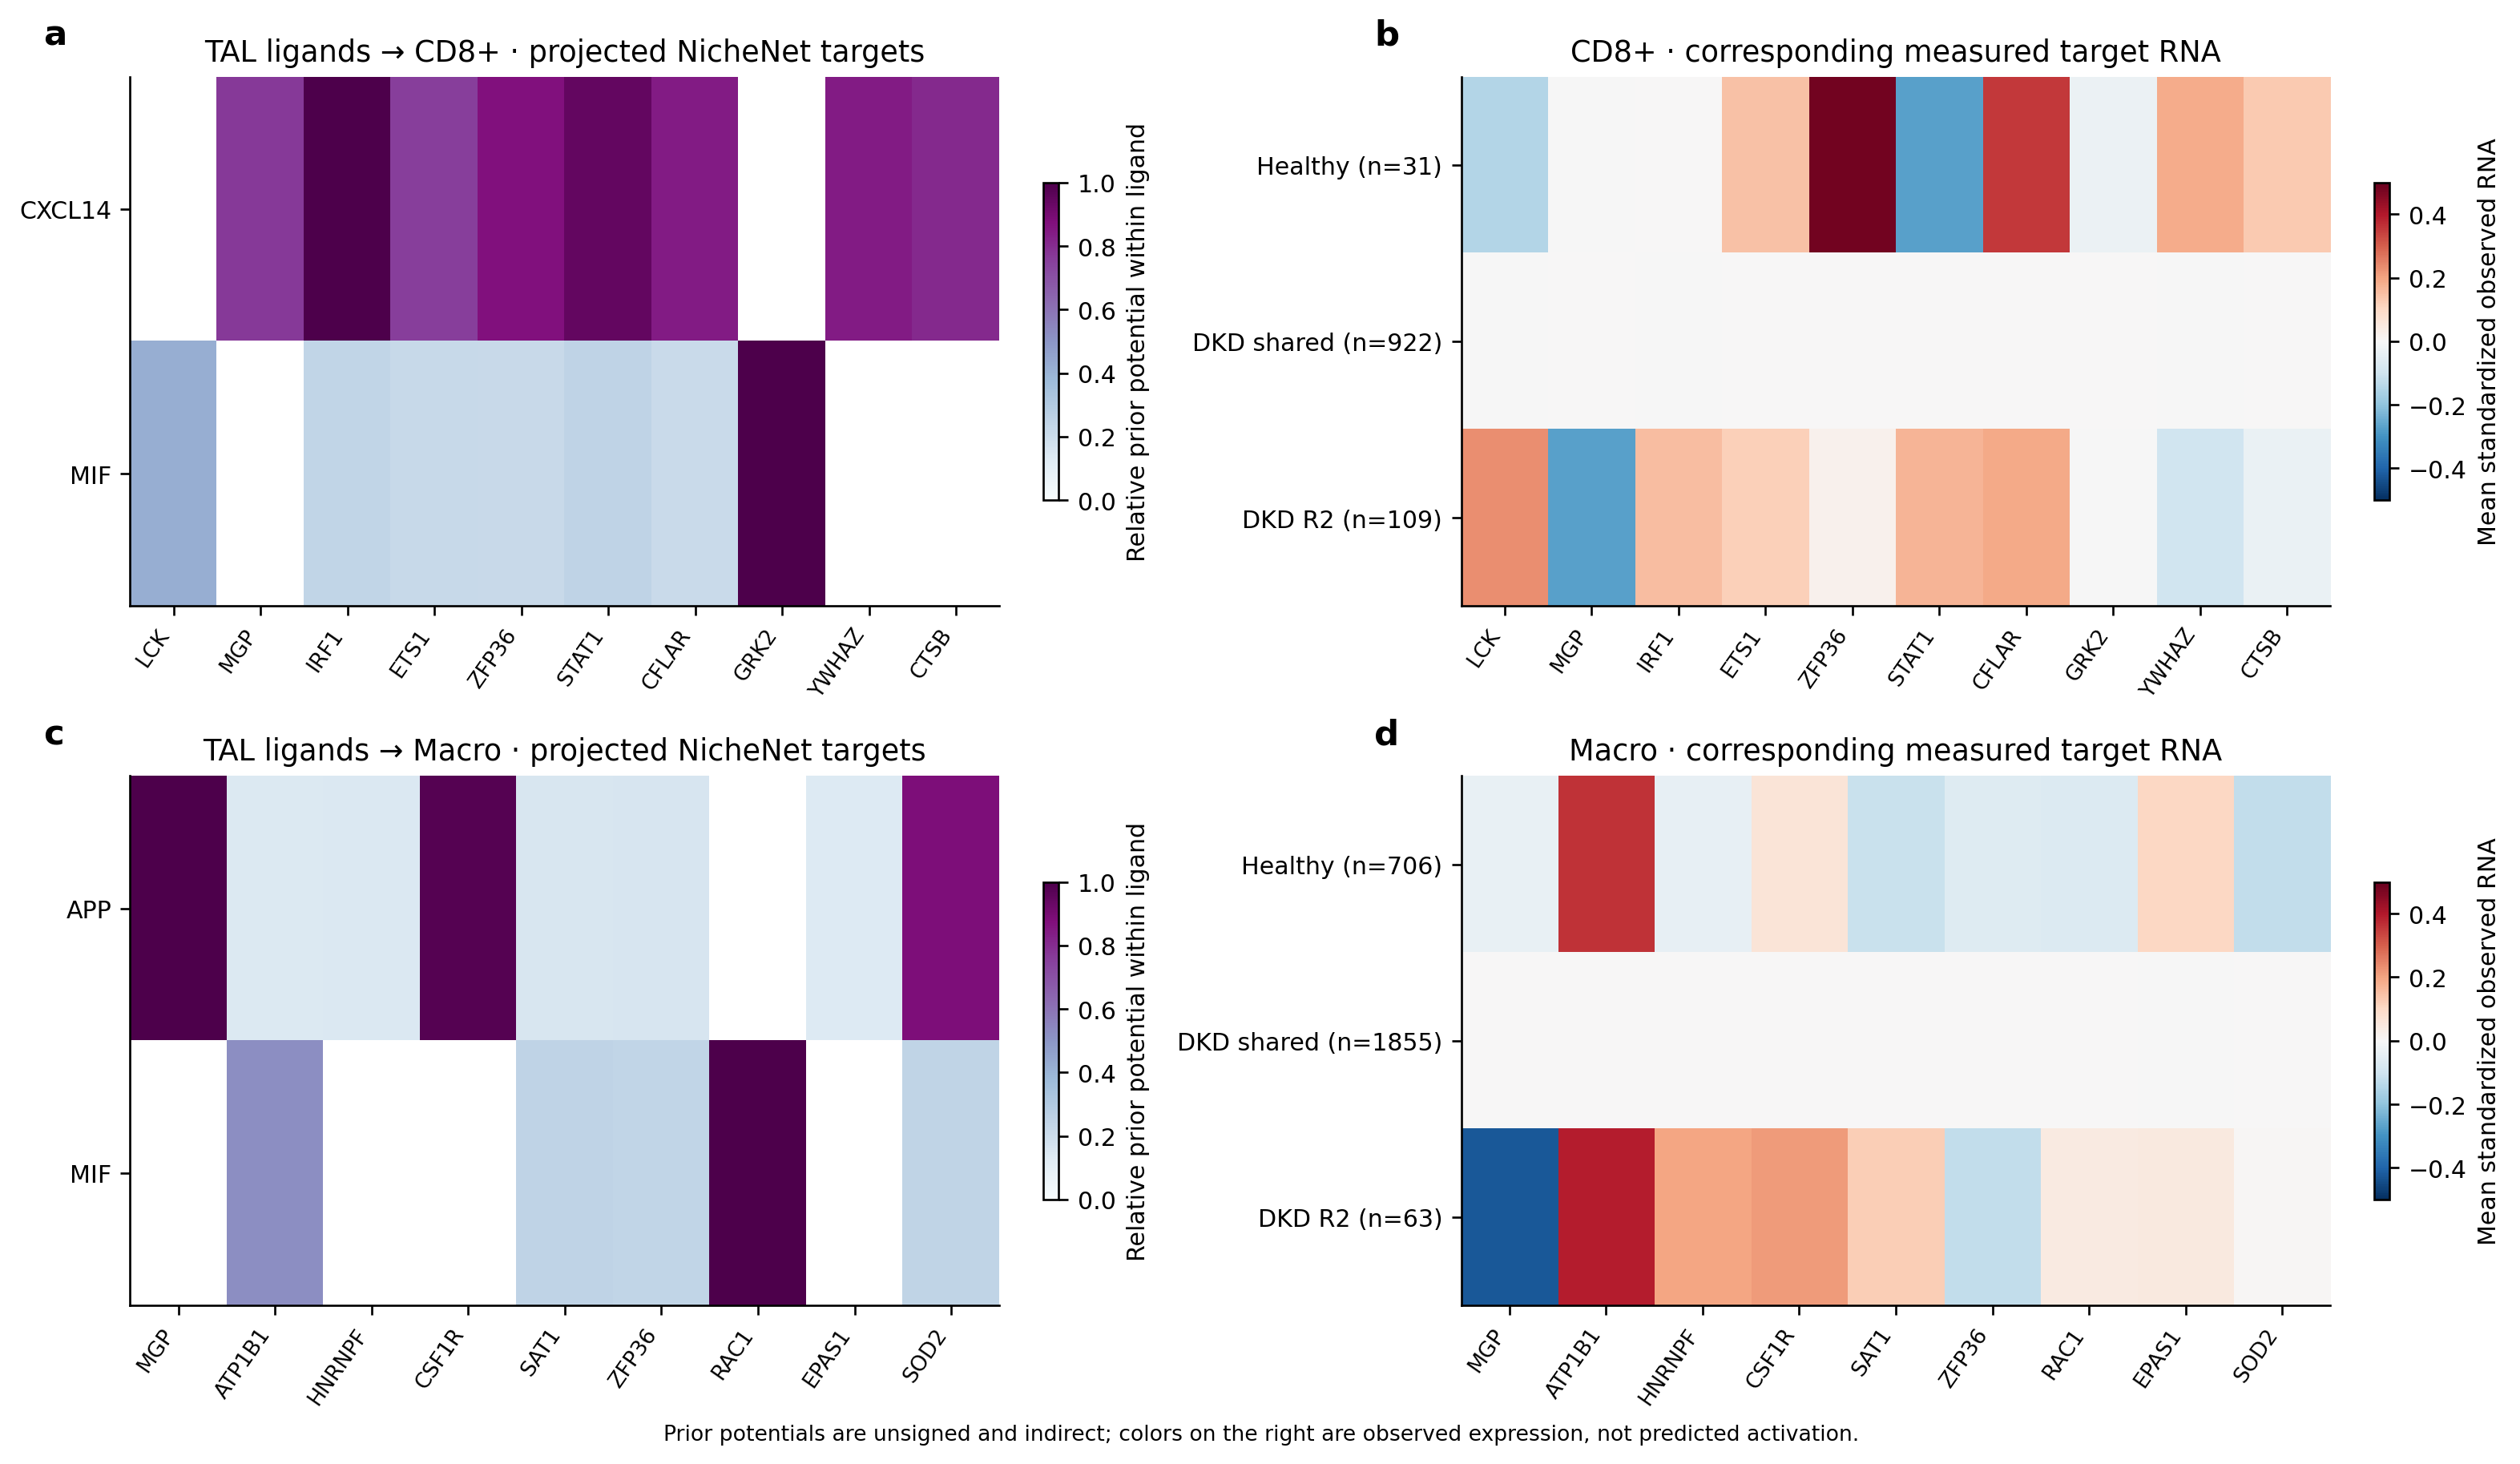

In [13]:
show(receiver.ligand_targets())

## 13 · 空间上 ligand 暴露较高处，接收端响应是否也改变？

上排：固定先验投影靶基因的实际平均表达评分；同类型 DKD 共有背景为零。下排：所有 DKD 同类型接收细胞中，周围 TAL 的 ligand 表达与接收端非 LR 靶基因评分的关联。暴露复用原 KNN30 物理细胞对及空间权重，重复物理边取其原权重均值；不乘接收细胞自身 receptor/target 表达，因此没有直接把响应放入暴露公式。

先调整接收端测序深度、检测基因数、自身 receptor RNA、TAL 配对机会和局部组成3个主成分，再取160µm空间块均值（至少3个接收细胞）；每点一个块，颜色表示 R2 占比。区间来自499次空间块 bootstrap，描述本切片局部关联，不当作患者数或因果证据。预先固定展示 CXCL14→CD8⁺、APP→Macro、MIF→Macro，保留正、负和不明确的结果，不按关联显著性挑图。

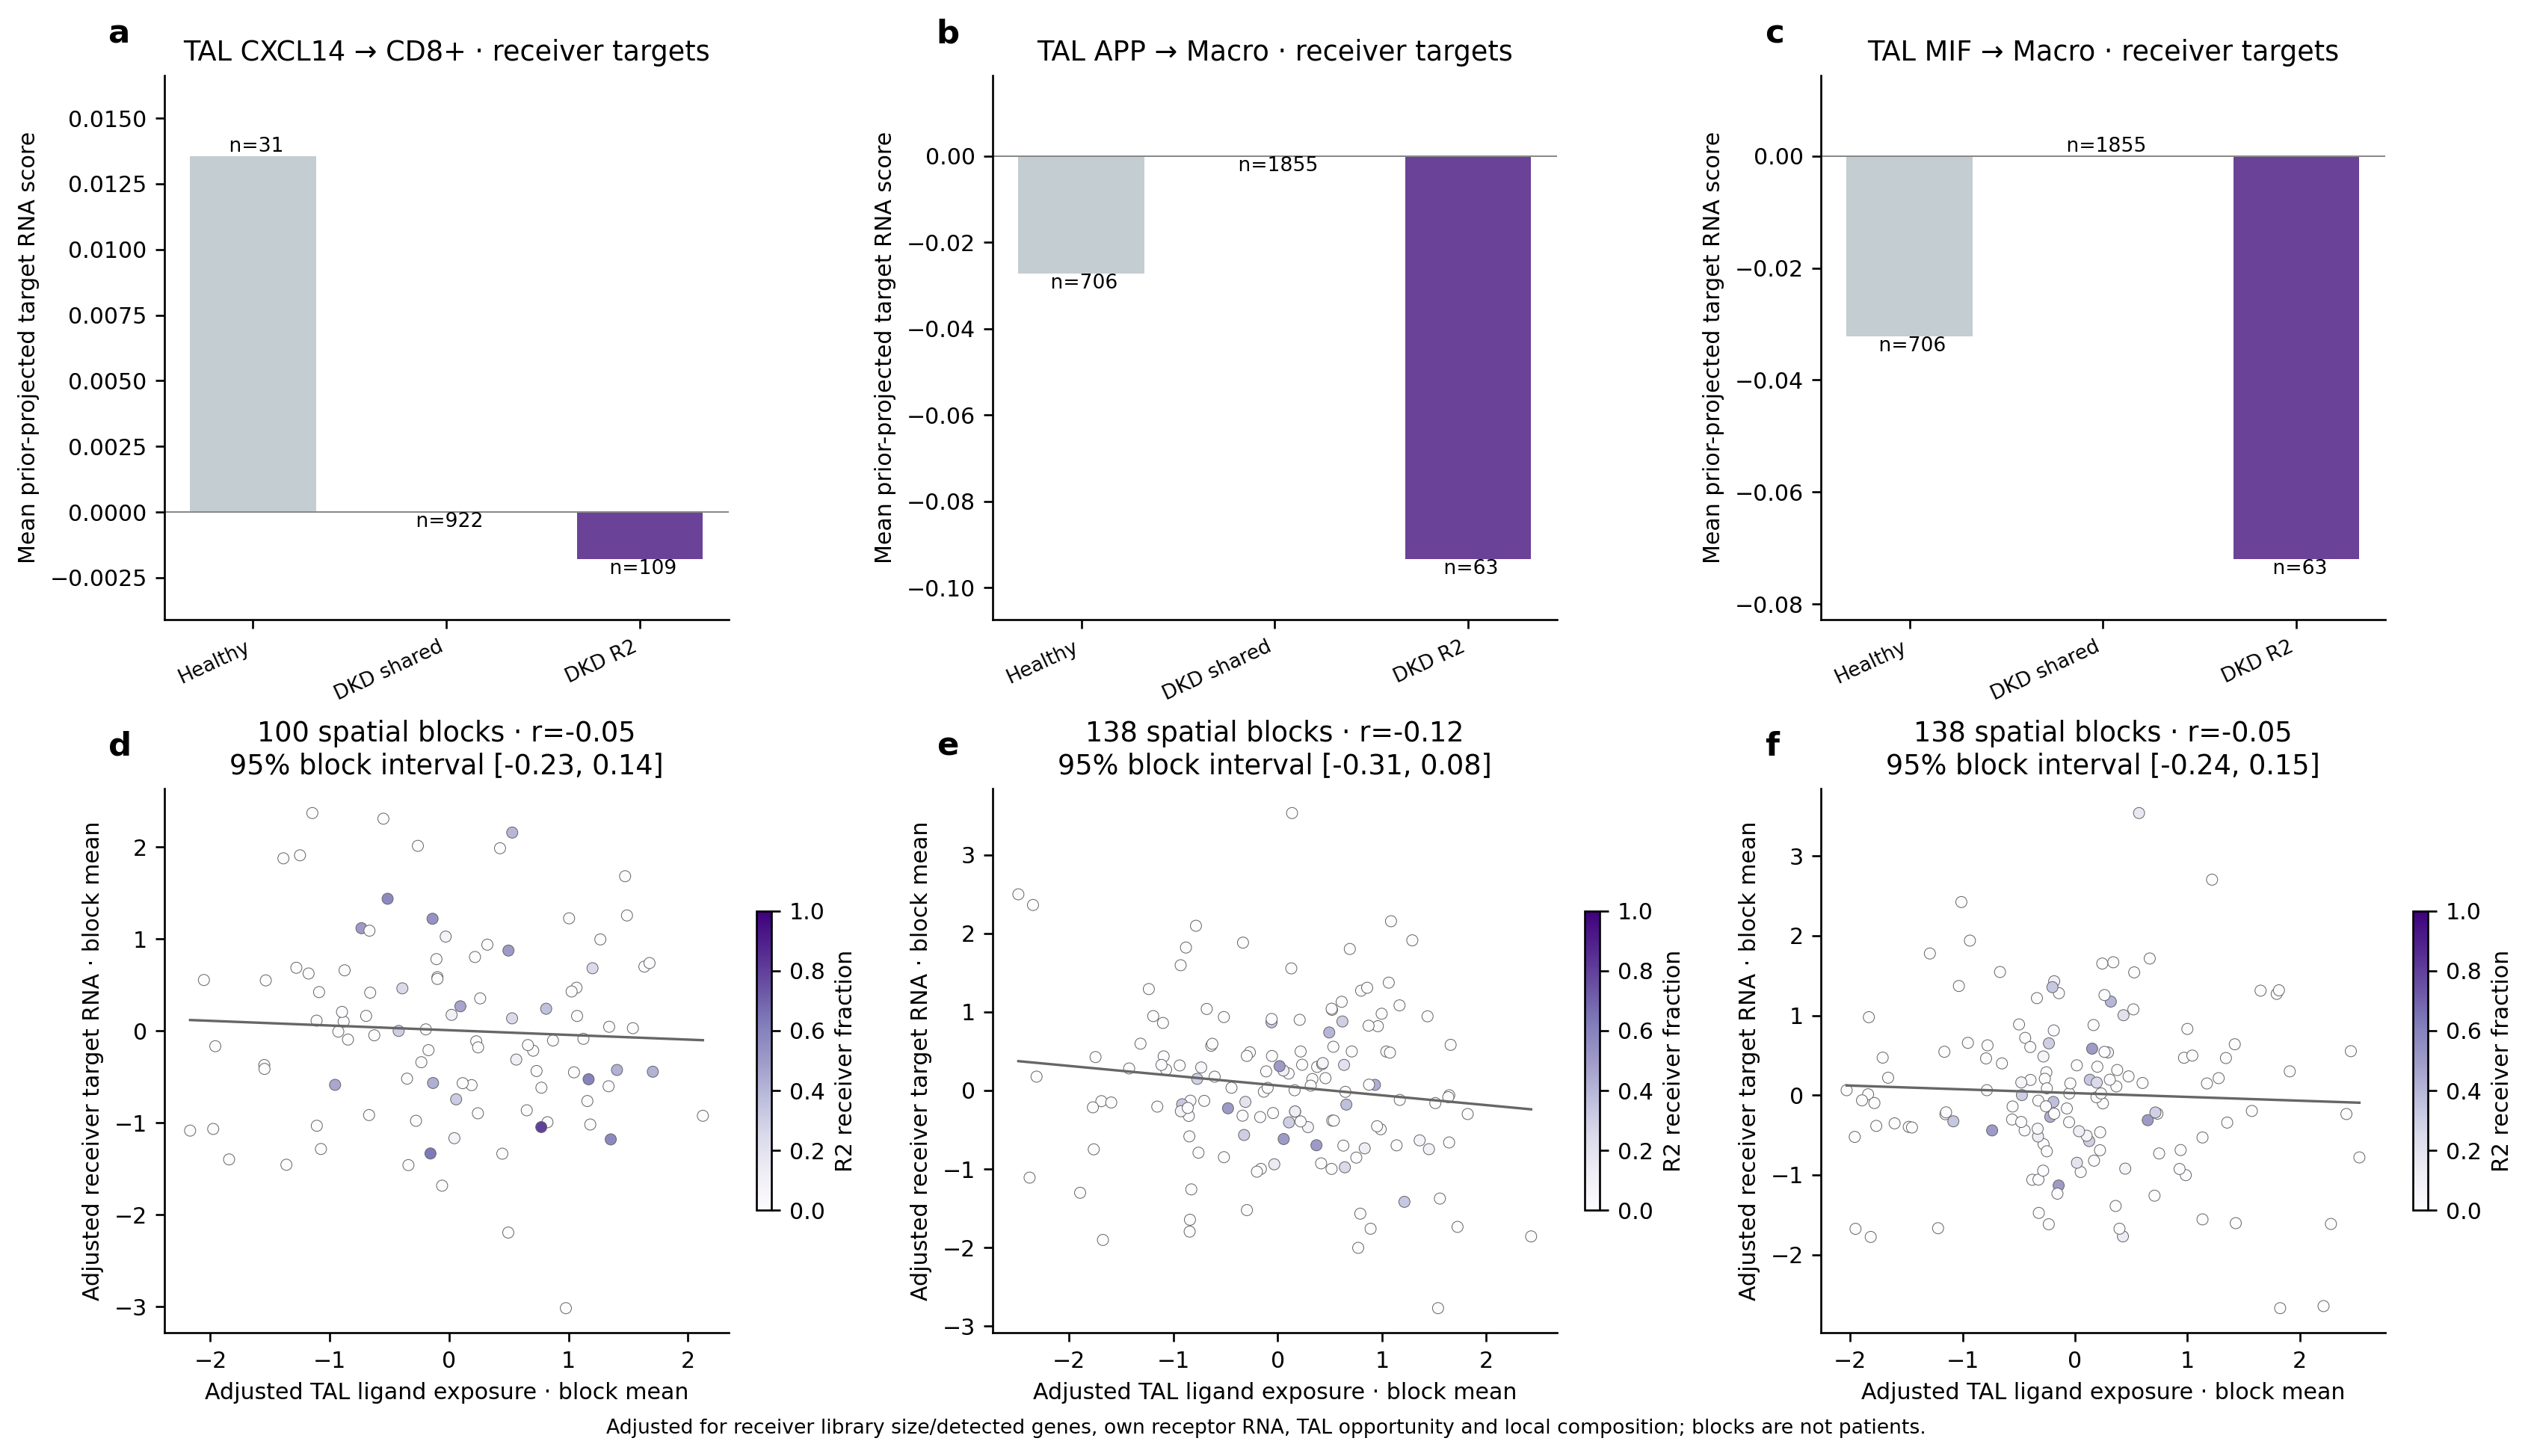

,候选通讯,同类细胞对内CCC占比（健康→R2）,R2非LR靶基因评分（同片共有背景=0）,调整后空间关联及95%块区间
0,TAL → CD8+ · CXCL14–CXCR4,4.3% → 14.9%,-0.002,"r=-0.05 [-0.23, 0.14]"
1,TAL → Macro · APP–CD74,68.4% → 72.9%,-0.093,"r=-0.12 [-0.31, 0.08]"
2,TAL → Macro · MIF–CD74,22.2% → 17.3%,-0.072,"r=-0.05 [-0.24, 0.15]"


Receiver response source data: /home/nas3/biod/xueshuailin/CCC_Phe/workspace/outputs/kidney_dkd_5k/HK3106_HK2695/downstream/receiver_response


In [14]:
show(receiver.spatial_response())
display(receiver.evidence_table())
print('Receiver response source data:',receiver_path)